# 1 Dataset Introduction

Financial markets are closely linked: the price of one asset is often affected by movements in stock markets, other commodities, currencies and the wider economy. Gold is a common example. Investors often treat it as a "safe haven" and buy it when stock markets fall or inflation rises, and because it is priced in US dollars it also responds to changes in the dollar's value and in interest rates.

This dataset brings these factors together in one daily record, covering two major US stock indices (the S&P 500 and NASDAQ), five commodities (gold, silver, oil, platinum and palladium), two exchange rates and three US economic indicators. This makes it suitable for studying how the assets relate to one another and for building models that predict a future price, such as gold, from the behaviour of the rest of the market.

## 1.1 Dataset Identification

The dataset was retrieved from Kaggle, where it was published by the user franciscogcc under the title "Gold Price Regression". It is a daily time series of financial information for market indices, commodities, economic indicators and foreign exchange rates. The market indices and commodities are represented by the price of the exchange-traded fund (ETF) that tracks each one, rather than by the index or spot price itself. Kaggle does not verify uploaded datasets, so this source should be treated with more caution than a curated repository such as UC Irvine. The dataset can be found at the following URL: 

https://www.kaggle.com/datasets/franciscogcc/financial-data

The dataset contains forty-seven (47) attributes over 3,904 rows, covering trading days from 14 January 2010 to 23 October 2024. The file does not define a target. As the dataset was published for regression on the gold price, gold close is treated as the target, with the remaining forty-six (46) attributes as features. The attributes are defined as the following types:

- <mark>Date</mark>: date Presented as a string in the format YYYY-MM-DD. For example: 2010-01-14.

- <mark>Numerical (Continuous)</mark>: the open, high, low and close prices of sp500, nasdaq, silver, oil, platinum, palladium and gold; the daily range (high-low) of each asset except gold; the exchange rates usd_chf and eur_usd; and the macroeconomic indicators us_rates_%, CPI and GDP (39 attributes in total). Prices and rates can take any real value and have no defined upper limit.

- <mark>Numerical (Discrete)</mark>: sp500 volume, nasdaq volume, silver volume, oil volume, platinum volume, palladium volume, gold volume. Volumes are counts of units traded, so they only take whole-number values, although the file stores them as decimals.

There are no categorical attributes. Around 5% of rows are empty apart from the date; these appear to be non-trading days. us_rates_%, CPI and GDP are published monthly or quarterly, so they are present on only around 5%, 5% and 1% of rows respectively. They would need to be forward-filled or removed before modelling. Table 1 summarises the attributes.

| Attribute(s) | Data type | Variable type | Description |
|---|---|---|---|
| date | String | Date | Trading day (YYYY-MM-DD) |
| [asset] open / high / low / close | Float | Numerical (continuous) | ETF price at open, highest, lowest and at close of the day |
| [asset] high-low | Float | Numerical (continuous) | Daily price range (high minus low) |
| [asset] volume | Float | Numerical (discrete) | Number of units traded that day |
| usd_chf, eur_usd | Float | Numerical (continuous) | Exchange rates |
| us_rates_% | Float | Numerical (continuous) | US interest rate (%) |
| CPI, GDP | Float | Numerical (continuous) | US Consumer Price Index and Gross Domestic Product |
| gold close | Float | Numerical (continuous) | Target: gold ETF closing price |

## 1.2. Supervised Learning Task Identification

**Financial Regression**

Herein, the objective of the supervised learning task is to use regression techniques to accurately predict the closing price of gold (gold close). This can also be determined from the following:

- The target variable, gold close, is numerical (continuous), meaning it can take any value within a range rather than belonging to a fixed set of categories.
- The dataset contains no categorical attributes that could act as a class label; all attributes other than date are numerical.
- The data is an ordered daily time series, so the task is to estimate a future value from earlier values of gold and the other assets, rates and indicators.

A classification task can also be performed by deriving a categorical target from the data, such as whether the price of gold rises or falls on the following day. However, this is not the dataset's primary purpose.

# 2. Exploratory Data Analysis

With the identification of the dataset, and the supervised learning task being defined as Financial Regression and regression respectively, exploratory data analysis (EDA) can be undertaken to facilitate a deeper understanding of the structure of the data, as well as allowing for identification of issues with data quality (IBM, 2024). This is particularly important for this dataset, as it contains missing values on non-trading days and macroeconomic indicators (us_rates_%, CPI and GDP) that are only recorded monthly or quarterly. Furthermore, by creating visualisations of the dataset, it is easier to identify any patterns, trends, or correlations that are present between gold and the other assets, rates and indicators. With conclusions drawn from this exploration, suitable machine learning algorithms and models can be identified, and features can be engineered to improve the performance of the chosen model(s). These model(s) can then be evaluated for their efficacy when provided data of a similar format to the original dataset.

Within the following section, questions and assumptions about the dataset will be proposed. Then an explanation of how data will be split into training, validation, and testing sets will be provided; as the data is a time series, this split will be made chronologically rather than at random, so that the model is never trained on data from after the period it is tested on. This will be followed by EDA, defining the process and results, which will then be measured against the previously proposed questions and assumptions.

### 2.1 Question(s) identification

Research questions should allow the researcher or investigator to set out what they want to know as a hypothesis, regardless of whether the result support the hypothesis or not (Mayo et al., 2013). By providing well posed questions and assumptions the EDA process will be able to support or reject their claims (Lane, 2018). Table 2 below provides several questions related to the dataset and their associated assumptions.

| ID | Question | Assumption |
|---|---|---|
| RQ1 | Does the price of gold move with the stock market (sp500 and nasdaq)? | Gold is often bought as a "safe haven" when stock markets fall, so it is expected that daily changes in gold will show little or a slightly negative relationship with daily changes in the stock indices. Over the full period, however, both may show a positive relationship simply because both rose over time. |
| RQ2 | Do other precious metals (silver, platinum and palladium) move with gold? | It is expected that silver will show a strong positive correlation with gold, as both are traded as precious metals and stores of value. Platinum and palladium are expected to show a weaker relationship, as their prices depend more on industrial demand such as vehicle manufacturing. |
| RQ3 | Do interest rates (us_rates_%) impact the price of gold? | Gold pays no interest, so it is expected that higher interest rates will make it less attractive than interest-bearing assets, resulting in a negative relationship between interest rates and the price of gold. |
| RQ4 | Does the strength of the US dollar (eur_usd and usd_chf) impact the price of gold? | As gold is priced in US dollars, it is expected that a weaker dollar will coincide with a higher gold price. This would appear as a positive relationship with eur_usd and a negative relationship with usd_chf. |
| RQ5 | Does inflation (CPI) impact the price of gold? | Gold is commonly treated as a protection against inflation, so it is expected that periods of rising CPI will coincide with a rising gold price. As CPI is only recorded monthly, this relationship is expected to be visible over long periods rather than day to day. |
| RQ6 | Does the previous day's price of gold predict the next day's price? | It is expected that the previous day's closing price will be the strongest single predictor of the next day's price, as daily price changes are usually small relative to the price itself. |

2.2 Splitting the dataset
The dataset will be split into three groups; the training set, the validation set, and the testinG set. It is important to train the model on a distinct set of data to the testing data, otherwise the model may memorise the training data and overfit to it, making it unreliable in real-world scenarios where it is expected to perform on unseen data. (Apicella et al., 2024). This is also referred to as data-leakage, which refers to the unintentional provision of data from outside the training dataset during model training.

To split the data, the module train_test_split from Scikit learn is used to allocate two subsets of data. This initial split creates a training and testing dataset, the code for which is shown in Figure 2; to allow for accurate replication of this split, the random_state parameter is used. This parameter is used to control the random number generator for the random state. In this case, the number 42 has been used, and this value can be used again to perform the same split (Scikit Learn, 2024.)

In [37]:
import pandas as pd
import random as rand
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mglearn
from scipy.stats import randint, uniform

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import (train_test_split, KFold, learning_curve,
                                     validation_curve, GridSearchCV, RandomizedSearchCV,
                                     cross_val_score)

from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.pipeline import make_pipeline


from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, roc_auc_score)

In [3]:
DATA_PATH = "../../datasets/regression/"
price = pd.read_csv(DATA_PATH + "financial_regression.csv", parse_dates=["date"])
price = price.sort_values("date")

In [4]:
# Fill gaps in slow-moving columns with the last known value
fill_cols = ["us_rates_%", "CPI", "GDP", "usd_chf", "eur_usd"]
price[fill_cols] = price[fill_cols].ffill()

# Remove non-trading days (rows with no market data)
price = price.dropna(subset=["sp500 close"]).reset_index(drop=True)

# Target: next trading day's gold close
price["target"] = price["gold close"].shift(-1)

# Drop rows before the first GDP value (Jan-Mar 2010) and the final row, which has no next-day target
price = price.dropna().reset_index(drop=True)
print(len(price), "rows from", price["date"].min().date(), "to", price["date"].max().date())

3665 rows from 2010-04-01 to 2024-10-22


In [5]:
X = price.drop(columns=["date", "target"])
y = price["target"]

In [6]:
# Split off 70% training data & 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42)

# Split the temporary data in half: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42)

print(len(X_train), len(X_val), len(X_test))

# Training rows with their dates, in date order, used for EDA
train = price.loc[X_train.index].sort_values("date")

# Daily % changes are calculated on the full, consecutive series and then
# restricted to training days. Calculating them on the training rows alone
# would compare days that are not next to each other.
change_cols = [c for c in price.columns if c.endswith(" close")] + ["eur_usd", "usd_chf"]
daily_change = price[change_cols].pct_change() * 100
train_change = daily_change.loc[train.index]

2565 550 550


In [7]:
price.info()

<class 'pandas.DataFrame'>
RangeIndex: 3665 entries, 0 to 3664
Data columns (total 48 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   date                3665 non-null   datetime64[us]
 1   sp500 open          3665 non-null   float64       
 2   sp500 high          3665 non-null   float64       
 3   sp500 low           3665 non-null   float64       
 4   sp500 close         3665 non-null   float64       
 5   sp500 volume        3665 non-null   float64       
 6   sp500 high-low      3665 non-null   float64       
 7   nasdaq open         3665 non-null   float64       
 8   nasdaq high         3665 non-null   float64       
 9   nasdaq low          3665 non-null   float64       
 10  nasdaq close        3665 non-null   float64       
 11  nasdaq volume       3665 non-null   float64       
 12  nasdaq high-low     3665 non-null   float64       
 13  us_rates_%          3665 non-null   float64       
 14  CPI

In [8]:
price.head(10)

,date,sp500 open,sp500 high,sp500 low,sp500 close,sp500 volume,sp500 high-low,nasdaq open,nasdaq high,nasdaq low,...,palladium low,palladium close,palladium volume,palladium high-low,gold open,gold high,gold low,gold close,gold volume,target
0,2010-04-01,117.80,118.25,117.10,117.80,161083608.0,1.15,48.34,48.70,47.790,...,48.7730,48.92,135299.0,0.5470,109.97,110.4700,109.92,110.26,11370417.0,110.89
1,2010-04-05,118.25,118.84,117.92,118.76,105621743.0,0.92,48.26,48.72,48.140,...,49.1100,50.38,191249.0,1.8700,110.56,110.9837,110.27,110.89,8207564.0,111.03
2,2010-04-06,118.42,119.25,118.29,119.04,110194919.0,0.96,48.49,48.90,48.390,...,50.3101,50.81,226947.0,0.7899,110.89,111.5100,110.83,111.03,10321993.0,112.49
3,2010-04-07,118.80,119.36,117.81,118.36,184432309.0,1.55,48.69,48.87,48.370,...,50.5101,50.89,483783.0,0.7199,111.85,112.9300,111.77,112.49,19127617.0,112.65
4,2010-04-08,117.95,118.97,117.60,118.77,158495871.0,1.37,48.51,48.82,48.240,...,50.0800,50.56,382541.0,0.5500,112.47,112.9800,112.13,112.65,12444414.0,113.64
5,2010-04-09,119.02,119.60,118.80,119.55,132701705.0,0.80,48.77,49.05,48.635,...,50.8000,51.32,192829.0,0.5800,113.09,114.0700,112.74,113.64,16427638.0,113.01
6,2010-04-12,119.70,120.05,119.56,119.74,110200946.0,0.49,49.05,49.20,48.940,...,51.5600,51.94,172620.0,0.9000,113.64,114.1300,112.98,113.01,11118097.0,112.69
7,2010-04-13,119.62,120.04,119.00,119.83,121901060.0,1.04,49.02,49.35,48.860,...,51.4000,52.92,365120.0,1.5500,113.12,113.1600,112.06,112.69,10983964.0,113.03
8,2010-04-14,120.27,121.19,120.08,121.19,161608989.0,1.11,49.57,49.92,49.500,...,54.1600,54.74,373814.0,0.8400,113.23,113.6600,112.78,113.03,10573838.0,113.65
9,2010-04-15,120.99,121.57,120.95,121.29,144514805.0,0.62,49.88,50.19,49.870,...,54.2600,54.48,220926.0,0.6600,112.90,113.7100,112.85,113.65,10952007.0,111.24


In [9]:
train.describe()

,date,sp500 open,sp500 high,sp500 low,sp500 close,sp500 volume,sp500 high-low,nasdaq open,nasdaq high,nasdaq low,...,palladium low,palladium close,palladium volume,palladium high-low,gold open,gold high,gold low,gold close,gold volume,target
count,2565,2565.000000,2565.000000,2565.000000,2565.000000,2.565000e+03,2565.000000,2565.000000,2565.000000,2565.000000,...,2565.000000,2565.000000,2.565000e+03,2565.000000,2565.000000,2565.000000,2565.000000,2565.000000,2.565000e+03,2565.000000
mean,2017-08-09 01:43:17.894736,272.647689,274.114048,271.057641,272.710226,1.105902e+08,3.056407,184.873932,186.180050,183.443478,...,109.725644,110.877125,6.699962e+04,2.301534,145.955439,146.608641,145.269855,145.962260,9.453187e+06,146.020915
min,2010-04-05 00:00:00,103.110000,103.420000,101.620000,102.200000,2.027001e+07,0.320000,42.670000,42.821500,41.550000,...,40.700000,41.860000,3.157000e+03,0.256200,100.920000,100.990000,100.232600,100.500000,1.779705e+06,100.500000
25%,2014-01-06 00:00:00,180.980000,181.730000,180.570000,181.120000,6.616650e+07,1.320000,86.140000,86.500000,85.250000,...,69.120000,69.700000,2.041300e+04,0.879900,120.840000,121.310000,120.450000,120.840000,5.732725e+06,120.830000
50%,2017-09-07 00:00:00,246.720000,247.570000,244.950000,246.820000,9.047012e+07,2.170000,144.740000,145.555000,143.920000,...,84.597600,85.290000,3.671400e+04,1.430000,138.530000,139.250000,137.940000,138.910000,7.935647e+06,138.760000
75%,2021-03-16 00:00:00,379.870000,381.920000,375.530000,379.380000,1.341676e+08,3.820000,290.320000,293.110000,286.150000,...,144.198300,145.576400,7.957700e+04,2.765000,167.880000,168.550000,167.150000,167.900000,1.127853e+07,167.980000
max,2024-10-22 00:00:00,585.910000,586.120000,582.160000,583.630000,7.095045e+08,22.960000,503.070000,503.520000,498.390000,...,277.000100,295.000000,1.109129e+06,37.880000,253.060000,253.940000,252.520000,253.930000,9.369811e+07,253.930000
std,NaN,120.272528,120.892377,119.594364,120.283156,6.834298e+07,2.673719,121.889562,122.773419,120.873185,...,57.055059,57.872938,8.943696e+04,2.583570,29.509531,29.655179,29.309183,29.496485,6.175132e+06,29.549526


In [10]:
unique_values = price["sp500 high"].unique()
print(unique_values)

[118.25 118.84 119.25 ... 585.39 584.85 584.5 ]


## Univariate Analysis

The univariate analysis focuses on the target asset, gold, and uses the training set only.

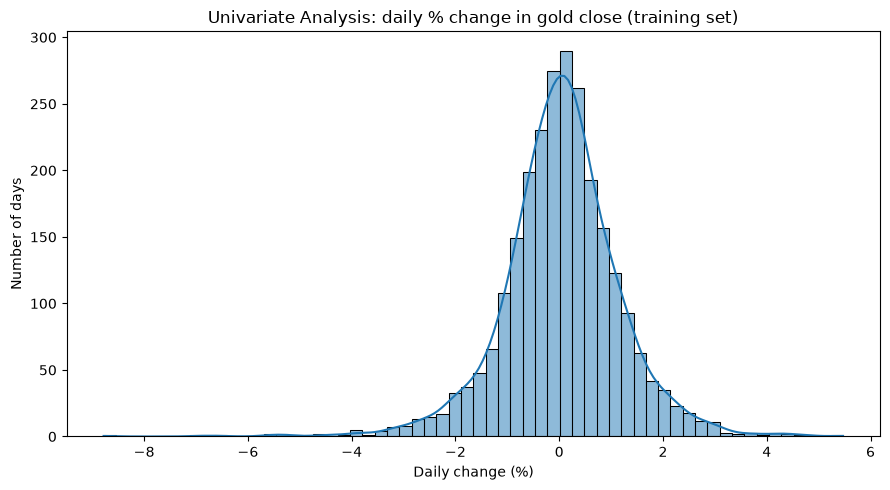

Mean absolute daily change: 0.82%


In [11]:
# Daily percentage change in gold close: the size of a typical day-to-day move
gold_return = train["gold close"].pct_change() * 100

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(gold_return.dropna(), bins=60, kde=True, ax=ax)
ax.set_title("Univariate Analysis: daily % change in gold close (training set)")
ax.set_xlabel("Daily change (%)")
ax.set_ylabel("Number of days")
plt.tight_layout()
plt.show()

print(f"Mean absolute daily change: {gold_return.abs().mean():.2f}%")

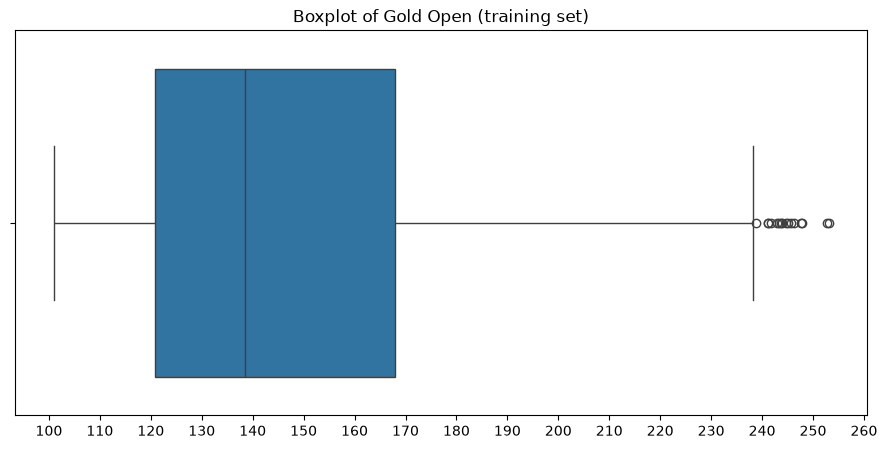

In [12]:
# Boxplot: gold open
plt.figure(figsize=(11, 5))

sns.boxplot(x = train["gold open"])
plt.title("Boxplot of Gold Open (training set)")
plt.xlabel("")

min_gold_open = np.floor(train["gold open"].min() / 10) * 10
max_gold_open = np.ceil(train["gold open"].max() / 10) * 10

plt.xticks(np.arange(min_gold_open, max_gold_open + 1, 10))

plt.show()

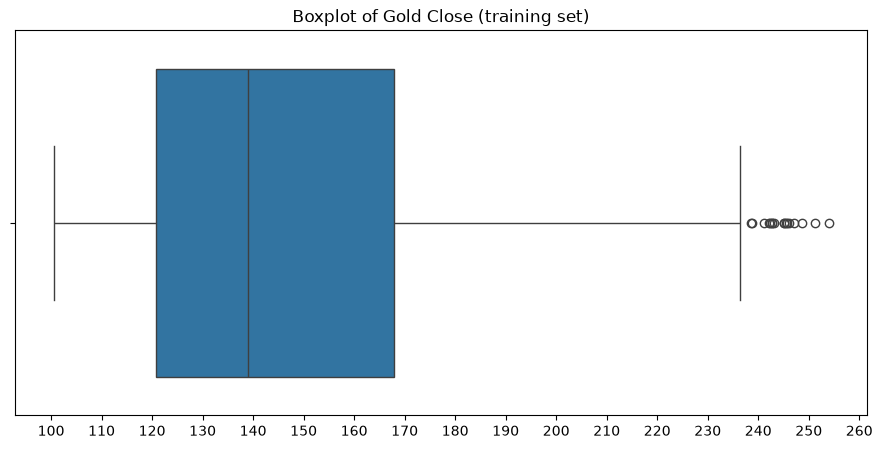

In [13]:
# Boxplot, gold close
plt.figure(figsize=(11, 5))

sns.boxplot(x = train["gold close"])
plt.title("Boxplot of Gold Close (training set)")
plt.xlabel("")

min_gold_close = np.floor(train["gold close"].min() / 10) * 10
max_gold_close = np.ceil(train["gold close"].max() / 10) * 10

plt.xticks(np.arange(min_gold_close, max_gold_close + 1, 10))

plt.show()

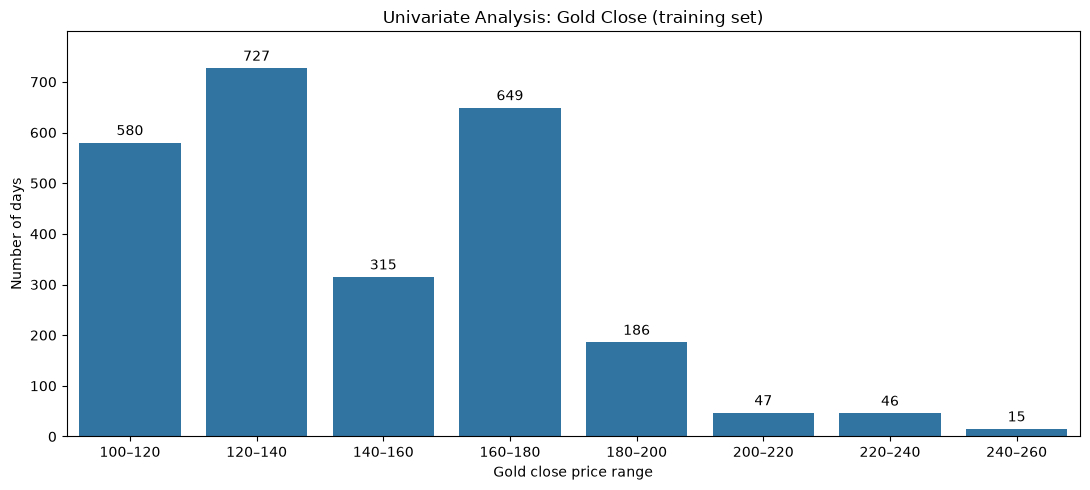

In [14]:
col = "gold close"

# Group prices into ranges of 20, covering the range present in the training set
low = int(np.floor(train[col].min() / 20) * 20)
high = int(np.ceil(train[col].max() / 20) * 20)
bins = np.arange(low, high + 1, 20)
labels = [f"{b}–{b + 20}" for b in bins[:-1]]
gold_close_range = pd.cut(train[col], bins=bins, labels=labels, right=False)

plt.figure(figsize=(11, 5))
gold_close_plot = sns.countplot(x=gold_close_range)

gold_close_plot.bar_label(gold_close_plot.containers[0], padding=3)

gold_close_plot.set_title("Univariate Analysis: Gold Close (training set)")
gold_close_plot.set_xlabel("Gold close price range")
gold_close_plot.set_ylabel("Number of days")
gold_close_plot.margins(y=0.1)

plt.tight_layout()
plt.show()

## Bivariate Analysis

The bivariate analysis tests each research question in Table 2 against the training set (April 2010 to June 2020).

Most of the prices in this dataset trend over time, so correlating price *levels* can show a strong relationship between two assets simply because both rose or fell over the same years. To separate genuine co-movement from shared trends, relationships are measured on both price levels and **daily percentage changes** (returns). Returns show whether two assets move together on the same day, which is what matters for predicting the next day's price.

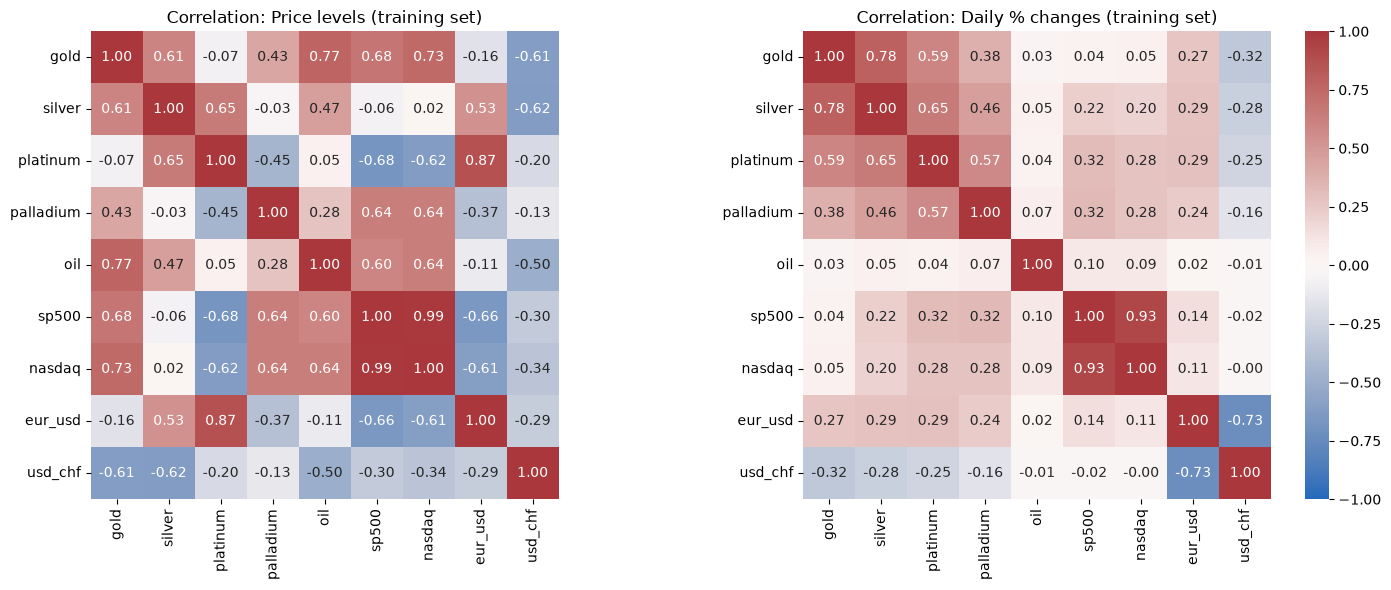

,level,daily change
silver,0.608,0.783
platinum,-0.074,0.595
palladium,0.426,0.375
oil,0.767,0.029
sp500,0.675,0.040
nasdaq,0.734,0.047
eur_usd,-0.159,0.272
usd_chf,-0.611,-0.324


In [15]:
price_cols = ["gold close", "silver close", "platinum close", "palladium close",
              "oil close", "sp500 close", "nasdaq close", "eur_usd", "usd_chf"]
short = {c: c.replace(" close", "") for c in price_cols}

levels = train[price_cols].rename(columns=short)
returns = train_change[price_cols].rename(columns=short)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, data, title in [(axes[0], levels, "Price levels"),
                        (axes[1], returns, "Daily % changes")]:
    sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
                square=True, cbar=ax is axes[1], ax=ax)
    ax.set_title(f"Correlation: {title} (training set)")
plt.tight_layout()
plt.show()

summary = pd.DataFrame({"level": levels.corr()["gold"],
                        "daily change": returns.corr()["gold"]}).drop("gold")
summary.round(3)

### RQ1: Does gold move with the stock market?

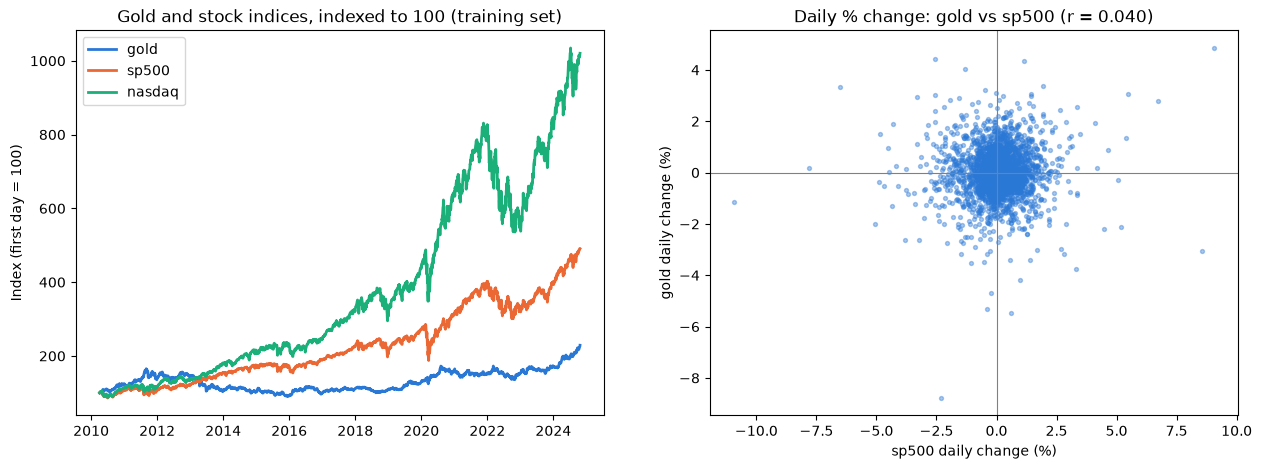

In [16]:
fig, axes= plt.subplots(1,2, figsize=(15,5))

indexed = train.set_index("date")[["gold close", "sp500 close", "nasdaq close"]]
indexed = indexed / indexed.iloc[0] * 100
for col, colour in zip(indexed.columns, ["#2a78d6", "#eb6834", "#1baf7a"]):
    axes[0].plot(indexed.index, indexed[col], color=colour, linewidth=2,
                 label=col.replace(" close", ""))
axes[0].set_title("Gold and stock indices, indexed to 100 (training set)")
axes[0].set_ylabel("Index (first day = 100)")
axes[0].legend()

# Right: same-day returns
r = train_change[["gold close", "sp500 close"]].dropna()
axes[1].scatter(r["sp500 close"], r["gold close"], s=8, alpha=0.4, color="#2a78d6")
axes[1].axhline(0, color="grey", linewidth=0.8)
axes[1].axvline(0, color="grey", linewidth=0.8)
axes[1].set_title(f"Daily % change: gold vs sp500 (r = {r.corr().iloc[0, 1]:.3f})")
axes[1].set_xlabel("sp500 daily change (%)")
axes[1].set_ylabel("gold daily change (%)")

plt.show()

Daily changes in gold show almost no relationship with daily changes in the stock indices (r ≈ 0.04 with sp500 and 0.05 with nasdaq), so the stock market gives little information about gold's next move. This partly supports the assumption: the relationship is close to zero, but slightly positive rather than negative.

As expected, price levels show a much stronger positive relationship (r ≈ 0.68 with sp500, 0.73 with nasdaq) because all three rose over the full period. The left-hand chart shows this is a shared trend rather than co-movement: gold fell from 2013 to 2015 while stocks rose, and the two only rose together from 2019 onwards. This shows why level correlations should not be read as evidence of a real relationship between trending series.

### RQ2: Do the other precious metals move with gold

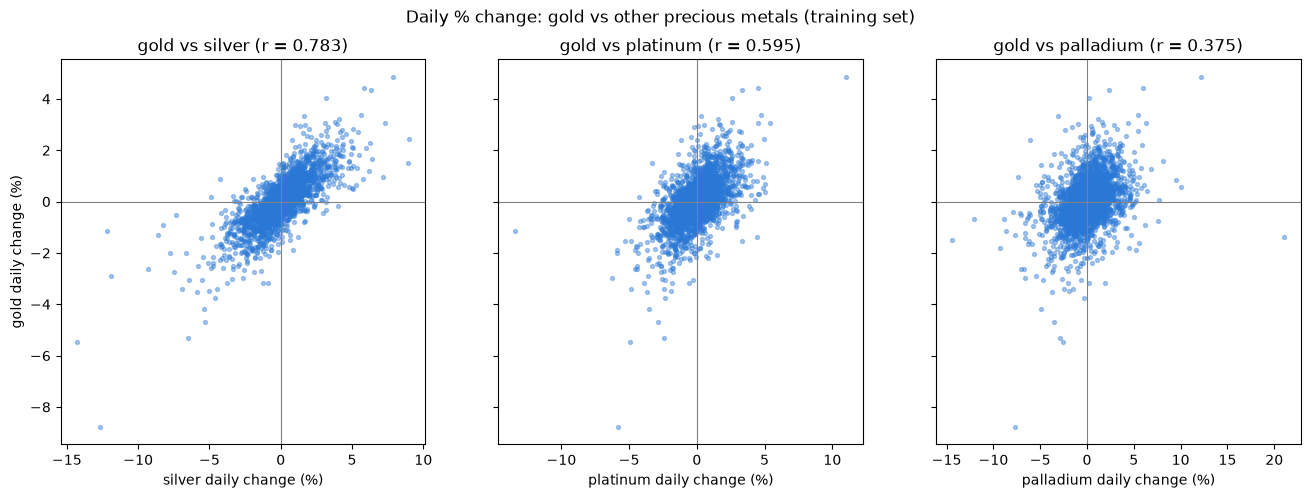

In [17]:
metals = ["silver close", "platinum close", "palladium close"]
r = train_change[["gold close"] + metals].dropna()

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, col in zip(axes, metals):
    ax.scatter(r[col], r["gold close"], s=8, alpha=0.4, color="#2a78d6")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.axvline(0, color="grey", linewidth=0.8)
    ax.set_title(f"gold vs {col.replace(' close', '')} (r = {r[col].corr(r['gold close']):.3f})")
    ax.set_xlabel(f"{col.replace(' close', '')} daily change (%)")
    
axes[0].set_ylabel("gold daily change (%)")
fig.suptitle("Daily % change: gold vs other precious metals (training set)")
plt.show()

The assumption is supported. Silver has the strongest relationship with gold of any asset in the dataset on daily changes (r ≈ 0.78). Platinum is moderately related (r ≈ 0.60) and palladium is weakest (r ≈ 0.38), consistent with their prices depending more on industrial demand. On price levels, the relationships are weaker and less consistent (silver 0.61, palladium 0.43, platinum -0.07), because each metal followed its own long-term trend: platinum, for example, fell for most of the period while gold rose. Because silver moves with gold on the same day rather than leading it, it explains today's gold price better than it predicts tomorrow's.

### RQ3: Do interest rates affect the price of gold?

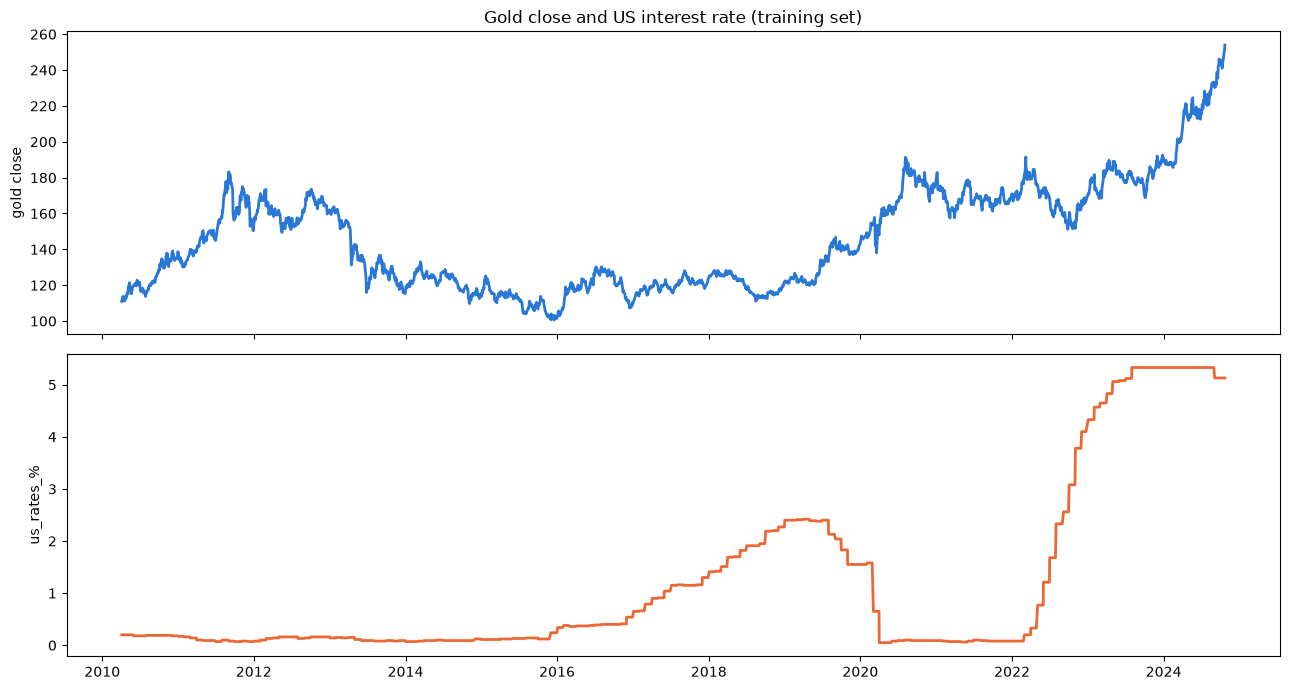

Level correlation (daily): 0.519
Monthly change in rate vs monthly % change in gold: -0.033


In [18]:
# Two panels sharing the date axis, rather than one chart with two y-axes
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(train["date"], train["gold close"], color="#2a78d6", linewidth=2)
axes[0].set_ylabel("gold close")
axes[0].set_title("Gold close and US interest rate (training set)")
axes[1].plot(train["date"], train["us_rates_%"], color="#eb6834", linewidth=2)
axes[1].set_ylabel("us_rates_%")
plt.tight_layout()
plt.show()

# Rates change monthly, so compare month-end values
monthly = train.set_index("date").resample("ME").last()
rate_change = monthly["us_rates_%"].diff()
gold_change = monthly["gold close"].pct_change() * 100
print(f"Level correlation (daily): {train['gold close'].corr(train['us_rates_%']):.3f}")
print(f"Monthly change in rate vs monthly % change in gold: {rate_change.corr(gold_change):.3f}")

The assumption is **not** supported by this data. Across the full period the level correlation is positive (r ≈ 0.52), the opposite of what was expected, and month-to-month changes in the rate show essentially no relationship with gold (r ≈ -0.03). The charts show why: between 2016 and 2018 rates rose while gold stayed low, which fits the assumption, but from 2022 onwards rates rose sharply to above 5% while gold rose to the highest prices in the dataset. Gold's largest fall, in 2013, also happened while rates were close to zero. The level correlation is therefore driven mainly by both series being high at the end of the period, and other factors appear to have outweighed interest rates in 2022–2024. The rate is unlikely to help much with next-day prediction.

### RQ4: Does the strength of the US dollar affect gold?

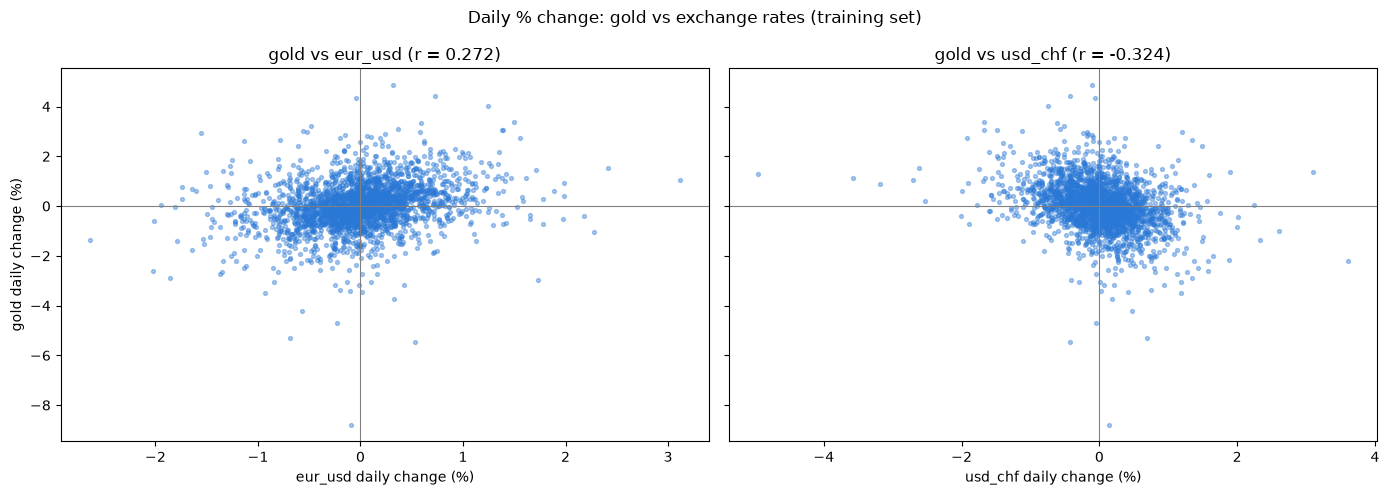

In [19]:
fx = ["eur_usd", "usd_chf"]
r = train_change[["gold close"] + fx].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, col in zip(axes, fx):
    ax.scatter(r[col], r["gold close"], s=8, alpha=0.4, color="#2a78d6")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.axvline(0, color="grey", linewidth=0.8)
    ax.set_title(f"gold vs {col} (r = {r[col].corr(r['gold close']):.3f})")
    ax.set_xlabel(f"{col} daily change (%)")
axes[0].set_ylabel("gold daily change (%)")
fig.suptitle("Daily % change: gold vs exchange rates (training set)")
plt.tight_layout()
plt.show()

The assumption is supported on daily changes. Gold rises on days when the dollar weakens: daily changes correlate positively with eur_usd (r ≈ 0.27, a rising eur_usd means a weaker dollar) and negatively with usd_chf (r ≈ -0.32). The relationship is moderate, and weaker than that of silver or platinum. On price levels the usd_chf relationship has the expected sign (r ≈ -0.61), but the eur_usd relationship is slightly negative (r ≈ -0.16), so over long periods the dollar's strength against the euro does not explain gold's price.

Note that the exchange-rate columns are recorded on slightly different days from the market data (17 values fall on non-trading days), which is handled by the forward-fill.

### RQ5: Does inflation affect the price of gold?

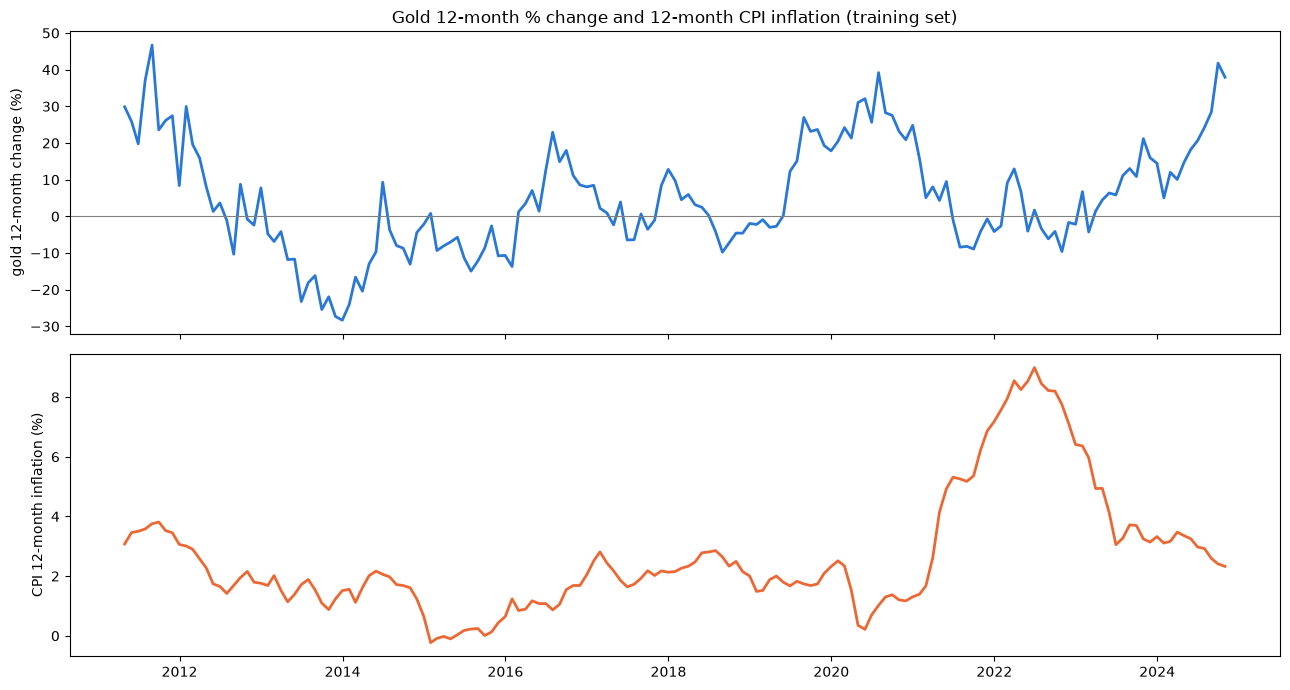

Level correlation, gold vs CPI: 0.706
12-month inflation vs gold 12-month change: 0.031


In [20]:
# CPI is monthly, so compare 12-month inflation with gold's 12-month % change
monthly = train.set_index("date").resample("ME").last()
inflation = monthly["CPI"].pct_change(12) * 100
gold_12m = monthly["gold close"].pct_change(12) * 100
both = pd.DataFrame({"inflation": inflation, "gold_12m": gold_12m}).dropna()

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(both.index, both["gold_12m"], color="#2a78d6", linewidth=2)
axes[0].axhline(0, color="grey", linewidth=0.8)
axes[0].set_ylabel("gold 12-month change (%)")
axes[0].set_title("Gold 12-month % change and 12-month CPI inflation (training set)")
axes[1].plot(both.index, both["inflation"], color="#eb6834", linewidth=2)
axes[1].set_ylabel("CPI 12-month inflation (%)")
plt.tight_layout()
plt.show()

print(f"Level correlation, gold vs CPI: {train['gold close'].corr(train['CPI']):.3f}")
print(f"12-month inflation vs gold 12-month change: {both.corr().iloc[0, 1]:.3f}")

The assumption is **not** supported by this data. The CPI level and gold are strongly correlated (r ≈ 0.71), but this mostly reflects both rising over time, as with the stock indices in RQ1. Comparing *rates of change* instead, 12-month inflation shows almost no relationship with gold's 12-month change (r ≈ 0.03). The clearest test is 2021–2022, when inflation rose to around 9%: gold did not rise with it, and its 12-month change was close to zero or negative through most of 2022. Gold's sharp rise in 2024 came while inflation was falling. In this data, gold has not acted as a reliable short-term protection against inflation. CPI is also unlikely to help with next-day prediction, as it changes only once a month.

### RQ6: Does the previous day's price predict the next day's price?

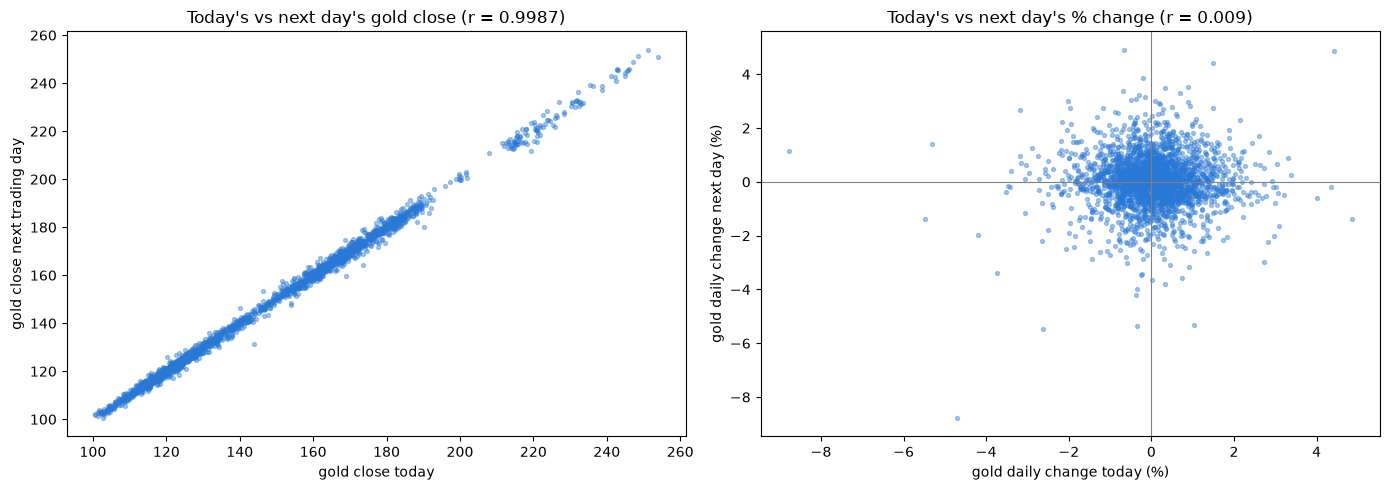

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(train["gold close"], train["target"], s=8, alpha=0.4, color="#2a78d6")
axes[0].set_title(f"Today's vs next day's gold close (r = {train['gold close'].corr(train['target']):.4f})")
axes[0].set_xlabel("gold close today")
axes[0].set_ylabel("gold close next trading day")

today = daily_change["gold close"].loc[train.index]
tomorrow = daily_change["gold close"].shift(-1).loc[train.index]
axes[1].scatter(today, tomorrow, s=8, alpha=0.4, color="#2a78d6")
axes[1].axhline(0, color="grey", linewidth=0.8)
axes[1].axvline(0, color="grey", linewidth=0.8)
axes[1].set_title(f"Today's vs next day's % change (r = {today.corr(tomorrow):.3f})")
axes[1].set_xlabel("gold daily change today (%)")
axes[1].set_ylabel("gold daily change next day (%)")

plt.tight_layout()
plt.show()

The assumption is strongly supported. Today's gold close and the next day's close are almost perfectly correlated (r ≈ 0.999), because a typical daily move is only about 0.7% of the price. This makes "tomorrow's price equals today's price" a very strong baseline that any model should be compared against.

However, the right-hand plot shows that the *direction* of today's move says almost nothing about tomorrow's move (r ≈ 0.01). Most of the predictive power comes from the price level, not from momentum, so the realistic aim for a model is to predict the small daily change better than this baseline.

### Summary of findings

| ID | Assumption | Result (training set) | Supported? |
|---|---|---|---|
| RQ1 | Little or slightly negative daily relationship with stocks; positive level relationship from shared growth | Daily r ≈ 0.04 (sp500); level r ≈ 0.68 (sp500) | Mostly (daily relationship slightly positive) |
| RQ2 | Silver strongly related; platinum and palladium weaker | Daily r: silver 0.78, platinum 0.60, palladium 0.38 | Yes |
| RQ3 | Higher rates, lower gold | Level r ≈ 0.52; monthly changes r ≈ -0.03 | No |
| RQ4 | Weaker dollar, higher gold | Daily r: eur_usd +0.27, usd_chf -0.32 | Yes (daily) |
| RQ5 | Rising inflation, rising gold, over long periods | 12-month r ≈ 0.03; level r ≈ 0.71 | No (level link reflects shared trend) |
| RQ6 | Previous close is the strongest predictor | Level r ≈ 0.999; daily change autocorrelation ≈ 0.01 | Yes |

**Implications for modelling:**

- Today's gold close should be kept as a feature, and every model should be compared against the naive baseline of predicting today's close.
- Silver, platinum and the exchange rates move with gold on the same day, so they are useful for explaining today's price, but none of the features shows a clear relationship with the *next* day's change. Models are therefore unlikely to improve much on the naive baseline.
- Because the random split places neighbouring days in the training set, test scores will be optimistic. Results should be interpreted with this limitation in mind (see Section 2.2).
- The volume columns reach around 10⁹ while prices are around 100. Features should be scaled (for example with StandardScaler in a pipeline) before fitting linear or distance-based models such as KNN, otherwise unscaled linear regression becomes numerically unstable.

## Multivariate Analysis

The bivariate analysis looked at gold against one variable at a time. Multivariate analysis looks at all of the attributes together, to answer two further questions that matter for modelling:

1. **Redundancy:** do several features carry the same information? The dataset has four prices per asset (open, high, low, close), and many assets trend together, so heavy overlap is expected (RQ6 in the sense of related features).
2. **Predictive signal:** does any combination of today's movements relate to the *next* day's change in gold, which is what a model has to predict?

As in the bivariate analysis, the training set is used throughout, and relationships are measured on both price levels and daily percentage changes.

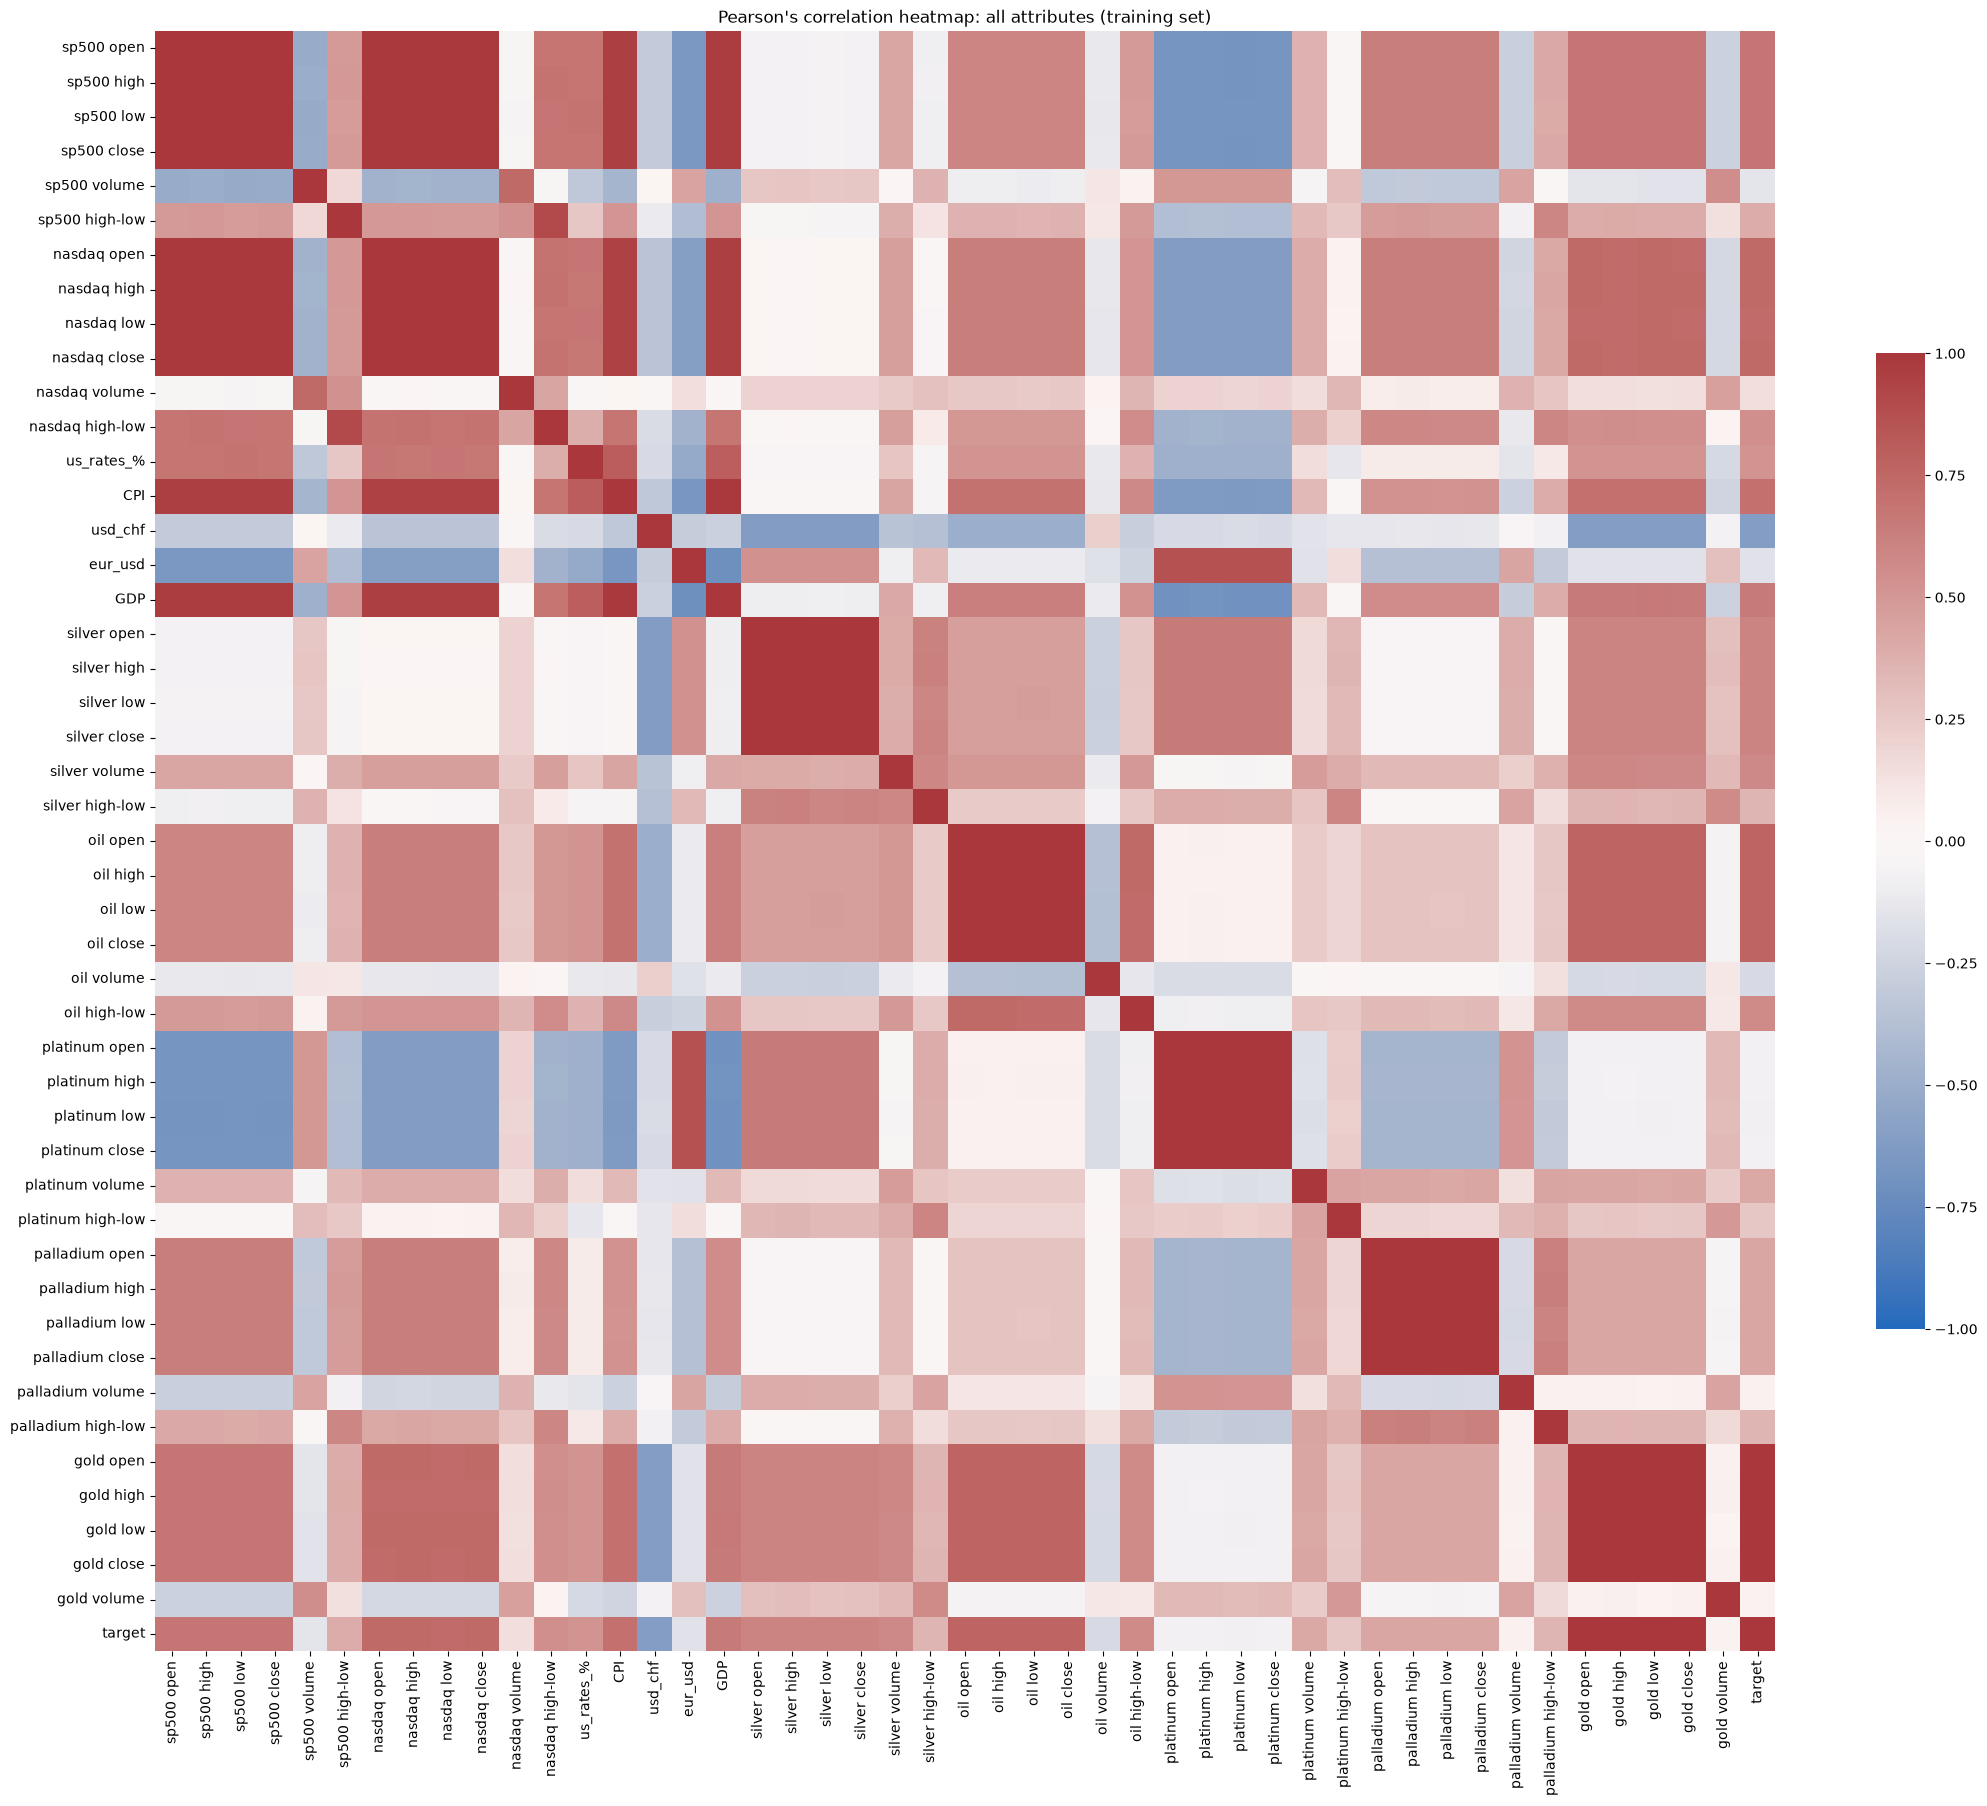

In [30]:
# Pearson Heatmap
corr = train.drop(columns="date").corr(method="pearson")

plt.figure(figsize=(22, 18))
sns.heatmap(corr, cmap="vlag", fmt=".3f", vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.6})

plt.title("Pearson's correlation heatmap: all attributes (training set)")
plt.tight_layout()
plt.show()

In [31]:
# List every pair of features with |r| above 0.95
pairs = corr.drop(index="target", columns="target").abs()
pairs = pairs.where(np.triu(np.ones(pairs.shape, dtype=bool), k=1)).stack()
high = pairs[pairs > 0.95].sort_values(ascending=False)

print("Feature pairs with |r| > 0.95:", len(high))
# Pairs that are NOT just open/high/low/close of the same asset
asset = lambda c: c.split(" ")[0]
cross = high[[asset(a) != asset(b) for a, b in high.index]]
print("\nOf which, between different assets or indicators:")
print(cross.round(3).to_string())

Feature pairs with |r| > 0.95: 71

Of which, between different assets or indicators:
CPI           GDP             0.992
sp500 high    nasdaq high     0.992
              nasdaq open     0.992
sp500 close   nasdaq close    0.992
sp500 high    nasdaq low      0.992
              nasdaq close    0.992
sp500 open    nasdaq open     0.992
sp500 close   nasdaq low      0.992
sp500 open    nasdaq low      0.992
sp500 close   nasdaq high     0.992
sp500 open    nasdaq high     0.992
sp500 low     nasdaq low      0.992
sp500 close   nasdaq open     0.991
sp500 open    nasdaq close    0.991
sp500 low     nasdaq open     0.991
              nasdaq close    0.991
              nasdaq high     0.991
sp500 high    GDP             0.971
sp500 close   GDP             0.970
sp500 open    GDP             0.970
sp500 low     GDP             0.970
nasdaq high   GDP             0.955
sp500 high    CPI             0.955
nasdaq open   GDP             0.955
nasdaq close  GDP             0.955
nasdaq low    G

### Redundancy between features

The heatmap shows solid blocks of near-perfect correlation along the diagonal: the open, high, low and close prices of each asset move almost identically, as a single day's price range is small compared with the price itself. 71 pairs of features have |r| > 0.95. 42 of these are prices of the same asset, and the other 29 are between different attributes:

- **sp500 and nasdaq** prices (r ≈ 0.99), as both indices track the US stock market.
- **CPI and GDP** (r ≈ 0.99), and both of these with the stock indices (r ≈ 0.95–0.97). These are not related day to day; they all simply rose steadily over the period.

The volume and high-low columns are much less correlated with the prices, so they carry information that the prices do not.

In [32]:
# Variance inflation factor: how well each feature is explained by all the others.
# VIF = 1 / (1 - R^2); values above 10 are usually treated as severe multicollinearity.
def vif_table(df):
    scaled = StandardScaler().fit_transform(df)
    out = {}
    for i, col in enumerate(df.columns):
        others = np.delete(scaled, i, axis=1)
        r2 = LinearRegression().fit(others, scaled[:, i]).score(others, scaled[:, i])
        out[col] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False)

features = train.drop(columns=["date", "target"])
close_only = ([c for c in features.columns if c.endswith(" close")]
              + ["usd_chf", "eur_usd", "us_rates_%", "CPI", "GDP"])

vif_all = vif_table(features)
vif_close = vif_table(features[close_only])
print(f"All 46 features: {(vif_all > 10).sum()} of {len(vif_all)} have VIF > 10")
print("\nClose prices and indicators only:")
print(vif_close.round(1).to_string())

All 46 features: 38 of 46 have VIF > 10

Close prices and indicators only:
CPI                390.6
GDP                325.9
sp500 close        197.8
nasdaq close       148.8
platinum close      24.8
oil close           24.2
gold close          16.6
us_rates_%          14.8
silver close         9.7
eur_usd              9.5
palladium close      4.4
usd_chf              4.1


Pairwise correlations only compare two features at a time. The variance inflation factor (VIF) measures how well each feature can be predicted from *all* the others combined, where a VIF above 10 is usually treated as severe multicollinearity. 38 of the 46 features have a VIF above 10.

Keeping only the close price of each asset reduces this considerably, but CPI (VIF ≈ 391), GDP (≈ 326), sp500 (≈ 198) and nasdaq (≈ 149) remain extremely high, because these four trend together over the whole period. Silver, palladium and the exchange rates fall below 10 once the duplicate open/high/low prices are removed.

Multicollinearity does not reduce the accuracy of tree-based models, but it makes the coefficients of a linear regression unstable and hard to interpret, and it gives distance-based models such as KNN several copies of the same information. Using only the close price of each asset, and choosing one of sp500/nasdaq and one of CPI/GDP, would remove most of this redundancy with little loss of information.

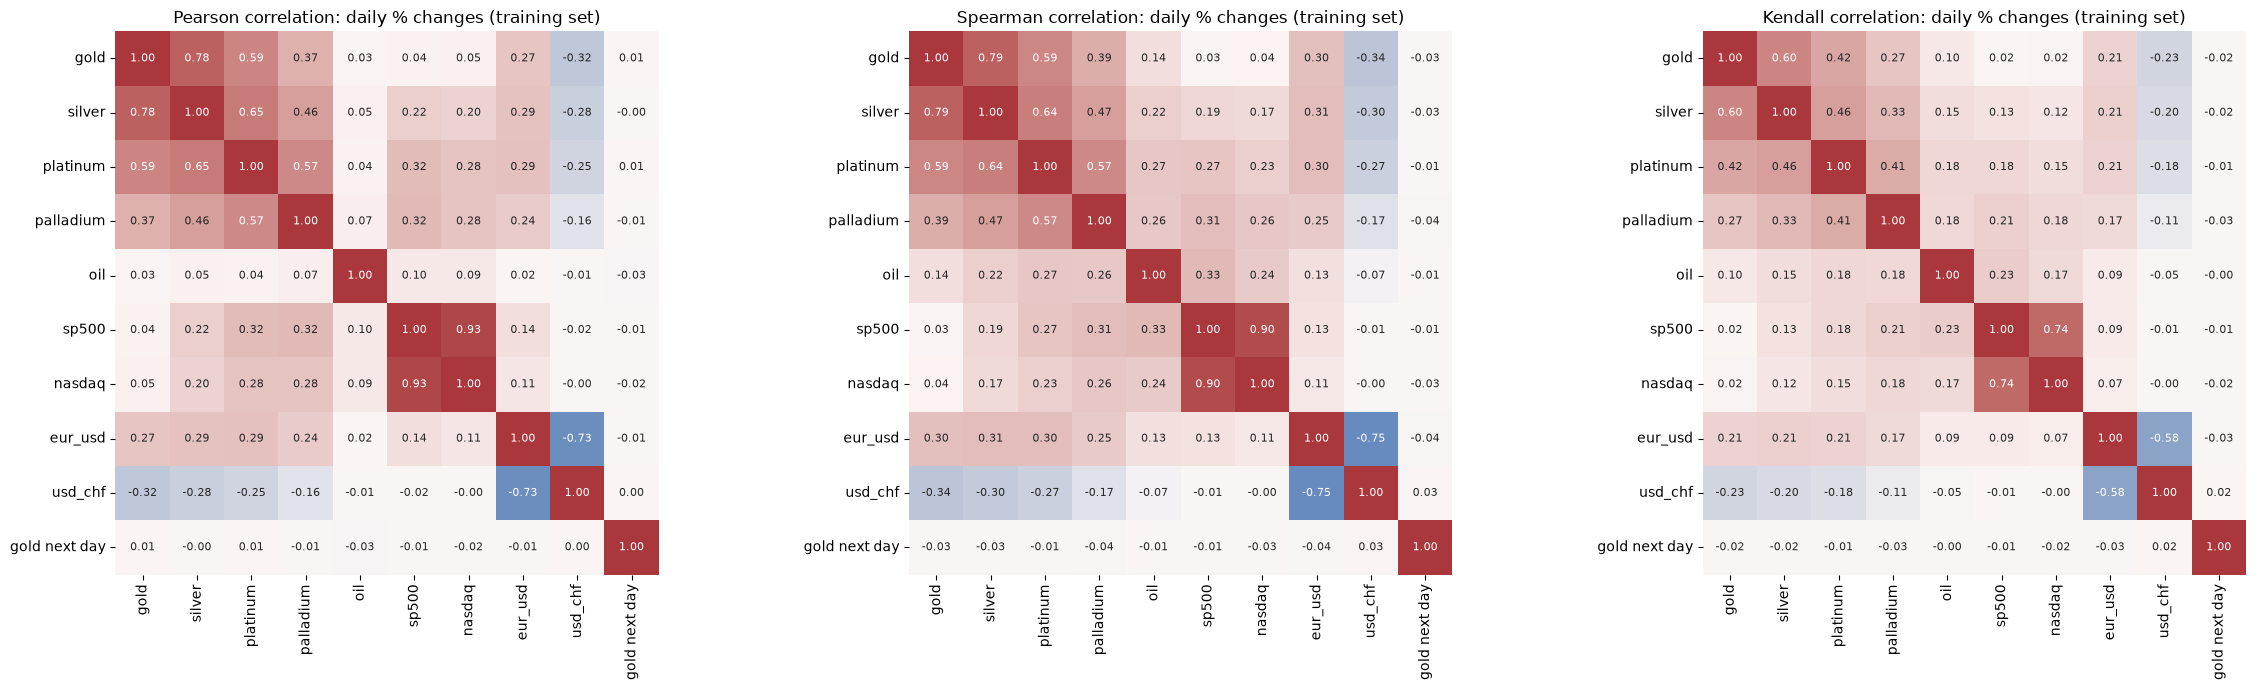

In [33]:
key = ["gold close", "silver close", "platinum close", "palladium close", "oil close",
       "sp500 close", "nasdaq close", "eur_usd", "usd_chf"]
names = {c: c.replace(" close", "") for c in key}
changes = train_change[key].rename(columns=names).dropna()
# Add the next day's gold change, the quantity a model actually has to predict
changes["gold next day"] = daily_change["gold close"].shift(-1).loc[changes.index]
changes = changes.dropna()

fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, method in zip(axes, ["pearson", "spearman", "kendall"]):
    sns.heatmap(changes.corr(method=method), annot=True, fmt=".2f", cmap="vlag",
                vmin=-1, vmax=1, square=True, cbar=False, ax=ax,
                annot_kws={"size": 8})
    ax.set_title(f"{method.title()} correlation: daily % changes (training set)")
plt.tight_layout()
plt.show()

### Linear and rank correlations of daily changes

Pearson's correlation measures straight-line relationships and is sensitive to extreme values. Spearman's and Kendall's correlations use ranks instead, so they also capture relationships that are consistent but not linear, and are less affected by outliers. Kendall's values are always smaller in size than Spearman's for the same data, so the two are compared by their pattern rather than their values.

All three methods give the same picture for same-day changes: gold moves most closely with silver (Pearson 0.78, Spearman 0.79), then platinum (0.59) and palladium (0.37–0.39), and against the dollar (usd_chf -0.32 to -0.34). The one notable difference is oil, which shows almost no linear relationship with gold (Pearson 0.03) but a weak rank relationship (Spearman 0.14). This suggests a few extreme oil price moves, such as the collapse in oil prices in 2020, are hiding a small, consistent tendency for the two to move in the same direction.

The final row of each heatmap is the most important for modelling. None of today's changes, including gold's own, has a meaningful relationship with **the next day's** gold change (all Spearman values between -0.04 and 0.03). The strong same-day relationships do not carry over to the following day.

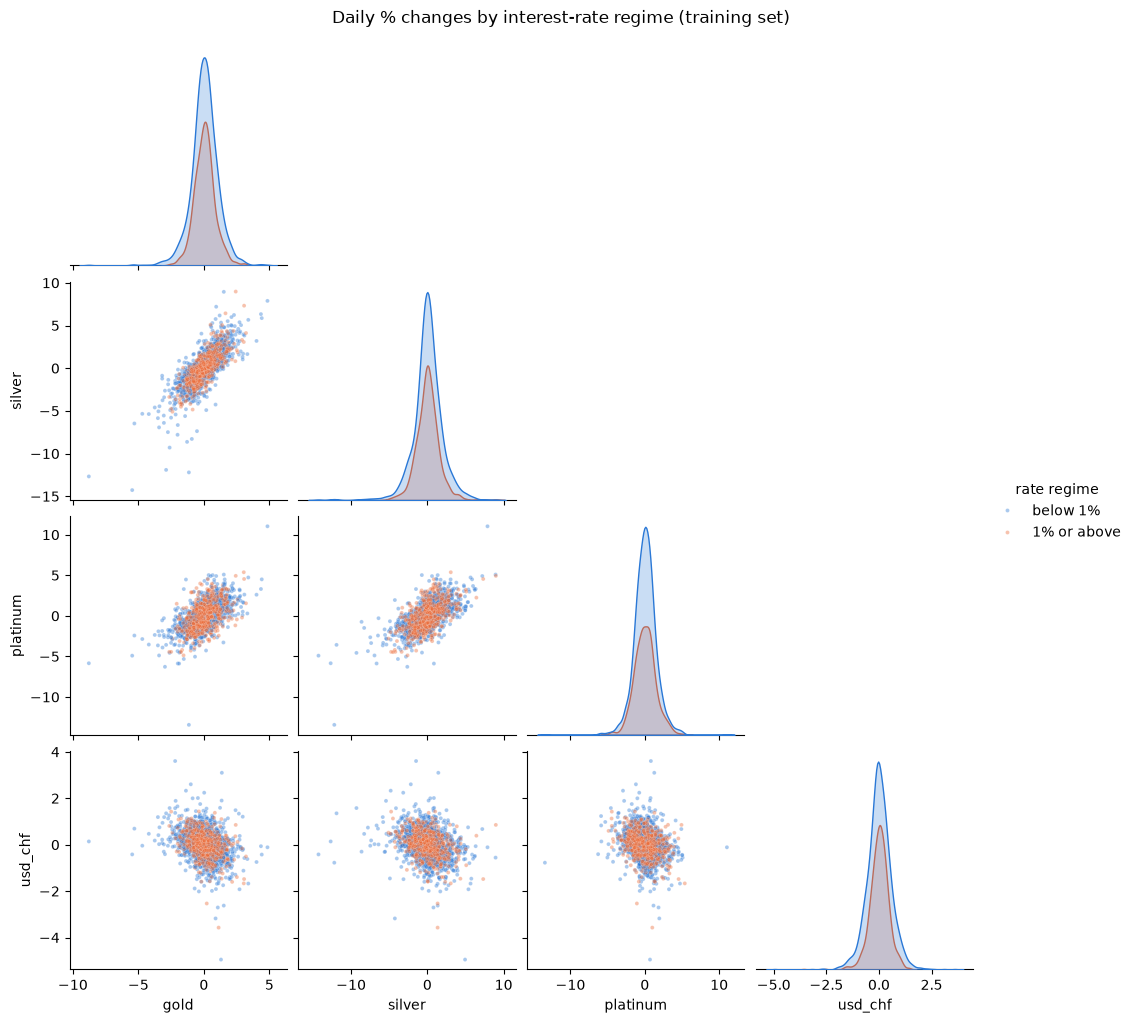

1% or above  n=929   silver: 0.79  platinum: 0.53  usd_chf: -0.38
below 1%     n=1636  silver: 0.78  platinum: 0.63  usd_chf: -0.31


In [34]:
# Does the relationship between gold and the other assets change with interest rates?
pp = train_change[["gold close", "silver close", "platinum close", "usd_chf"]].copy()
pp.columns = ["gold", "silver", "platinum", "usd_chf"]
pp["rate regime"] = np.where(train["us_rates_%"] < 1, "below 1%", "1% or above")
pp = pp.dropna()

g = sns.pairplot(pp, hue="rate regime", hue_order=["below 1%", "1% or above"],
                 palette=["#2a78d6", "#eb6834"], corner=True,
                 plot_kws={"s": 8, "alpha": 0.4}, diag_kind="kde")
g.figure.suptitle("Daily % changes by interest-rate regime (training set)", y=1.02)
plt.show()

for regime, part in pp.groupby("rate regime"):
    c = part.drop(columns="rate regime").corr()["gold"].drop("gold")
    print(f"{regime:<12} n={len(part):<5}", "  ".join(f"{k}: {v:.2f}" for k, v in c.items()))

### Relationships under different interest-rates

RQ3 found little direct link between interest rates and gold. The pair plot checks whether the rate level instead changes how gold relates to the other assets, by splitting the training days into those with US rates below 1% (1,636 days) and 1% or above (929 days).

The relationships are broadly stable. Gold's link with silver is almost unchanged (r ≈ 0.78 and 0.79). When rates are higher, gold is slightly more closely tied to the dollar (usd_chf -0.31 → -0.38) and less closely to platinum (0.63 → 0.53). These differences are small, so adding the interest rate as a feature is unlikely to change these relationships enough to improve predictions.

### Summary of multivariate findings

- The features contain a large amount of duplicate information: open/high/low/close of each asset, sp500 and nasdaq, and CPI, GDP and the stock indices over time. 38 of 46 features have VIF > 10. Feature selection (for example close prices only, one stock index and one of CPI/GDP) or a regularised model such as Ridge regression should be considered.
- Same-day relationships are consistent across Pearson, Spearman and Kendall correlations, with silver, platinum and the dollar most closely linked to gold.
- No feature, alone or as part of the correlation structure, shows a meaningful relationship with the next day's change in gold. This supports the conclusion of the bivariate analysis: the next day's price is predicted mainly by today's price, and other features are likely to add little.

# 3. Expiremental Design

Modelling

Four algorithms are compared: a DummyRegressor, linear regression, K-nearest neighbours (KNN) regression and a random forest. The EDA found that today's gold close predicts the next day's close almost perfectly (r ≈ 0.999), so a **naive baseline**, which predicts that tomorrow's close equals today's, is also included. This is the real benchmark: a model is only useful if it beats it.

Each model is tuned using the validation set only. Once all tuning is finished, every model is scored **once** on the test set, so the test set plays no part in choosing models or settings. Because every reasonable model reaches R² ≈ 0.99 from today's gold close alone, models are compared mainly on mean absolute error (MAE), the average size of a prediction's error in the price's own units, and root mean squared error (RMSE), which penalises large errors more heavily.

In [35]:
def scores(model, X_part, y_part):
    """R^2, MAE and RMSE of a fitted model on one part of the data."""
    pred = model.predict(X_part)
    return {"R2": r2_score(y_part, pred),
            "MAE": mean_absolute_error(y_part, pred),
            "RMSE": np.sqrt(mean_squared_error(y_part, pred))}

def report(name, model):
    """Print training and validation scores and store them for the comparison table."""
    tr, va = scores(model, X_train, y_train), scores(model, X_val, y_val)
    print(f"{name}")
    print(f"  Training set   R^2: {tr['R2']:.4f}  MAE: {tr['MAE']:.3f}  RMSE: {tr['RMSE']:.3f}")
    print(f"  Validation set R^2: {va['R2']:.4f}  MAE: {va['MAE']:.3f}  RMSE: {va['RMSE']:.3f}")
    models[name] = model

models = {}

# Naive baseline: predict that tomorrow's close equals today's close.
# It needs no training; wrapping it as a "model" lets it use the same scoring code.
class NaiveBaseline:
    def predict(self, X_part):
        return X_part["gold close"].values

report("Naive (tomorrow = today)", NaiveBaseline())

Naive (tomorrow = today)
  Training set   R^2: 0.9974  MAE: 1.046  RMSE: 1.497
  Validation set R^2: 0.9977  MAE: 1.025  RMSE: 1.423


### Dummy Regression

In [36]:
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
report("DummyRegressor (mean)", dummy)

DummyRegressor (mean)
  Training set   R^2: 0.0000  MAE: 25.486  RMSE: 29.544
  Validation set R^2: -0.0008  MAE: 25.256  RMSE: 29.517


The DummyRegressor predicts the mean training price for every day, ignoring all features. It gives an R² of 0 and an MAE of about 25, and sets the minimum standard any model must clearly beat.


### Linear Regression

In [38]:
# Scaling is part of the pipeline, so the scaler is fitted on the training set only
lr = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
report("Linear Regression", lr)

coef = pd.Series(lr.named_steps["linearregression"].coef_, index=X_train.columns)
print("\nLargest coefficients (scaled features):")
print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(8).round(3).to_string())

Linear Regression
  Training set   R^2: 0.9975  MAE: 1.042  RMSE: 1.483
  Validation set R^2: 0.9976  MAE: 1.031  RMSE: 1.434

Largest coefficients (scaled features):
gold close        29.393
gold high         -4.565
palladium open     2.989
platinum close     2.616
gold open          2.425
oil close         -2.242
gold low           2.130
nasdaq close      -2.060


The features are standardised before fitting. Without scaling, the volume columns (up to around 10⁹) make the calculation numerically unstable. Linear regression matches the naive baseline closely (validation MAE 1.031 vs 1.025), with almost identical training and validation scores, so it is not overfitting.

The coefficients confirm the EDA: gold close has by far the largest weight (29.4), and every other coefficient is small. Some, such as gold high (-4.6) against gold open and gold low (+2.4 and +2.1), have opposite signs despite measuring almost the same thing. This is the effect of the multicollinearity found in the multivariate analysis: the coefficients of near-duplicate features offset one another and should not be interpreted individually.

### KNN Regression


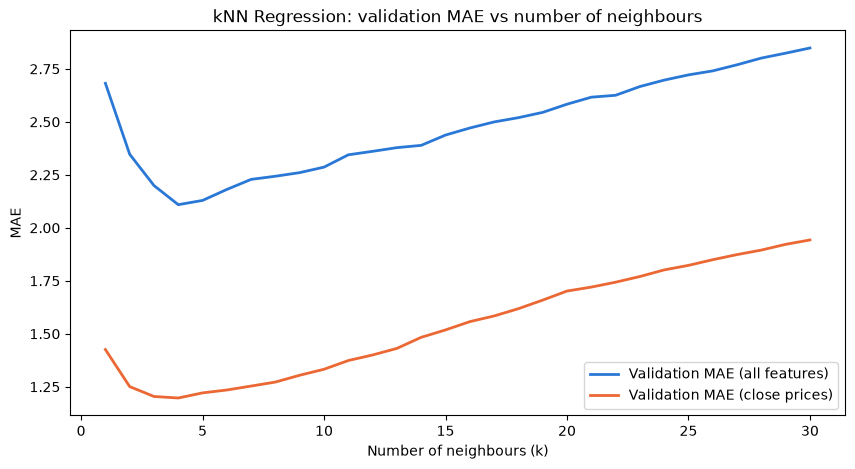

In [39]:
# KNN measures distance across all features, so duplicate features (see the
# multivariate analysis) count the same information several times.
# Two feature sets are compared: all 46 features, and one close price per asset
# plus the indicators (GDP is left out as it duplicates CPI).
close_cols = ([c for c in X_train.columns if c.endswith(" close")]
              + ["usd_chf", "eur_usd", "us_rates_%", "CPI"])
feature_sets = {"all features": list(X_train.columns), "close prices": close_cols}

def knn_model(k, cols):
    # Selecting the columns inside the pipeline lets the model take the full X
    select = FunctionTransformer(lambda X_part: X_part[cols])
    return make_pipeline(select, StandardScaler(), KNeighborsRegressor(n_neighbors=k))

# Try k = 1 to 30 for each feature set and score each on the validation set
k_values = range(1, 31)
knn_val = {}
for set_name, cols in feature_sets.items():
    knn_val[set_name] = [mean_absolute_error(y_val, knn_model(k, cols).fit(X_train, y_train).predict(X_val))
                         for k in k_values]

plt.figure(figsize=(10, 5))
for (set_name, maes), colour in zip(knn_val.items(), ["#2a78d6", "#eb6834"]):
    plt.plot(k_values, maes, color=colour, linewidth=2, label=f"Validation MAE ({set_name})")
plt.xlabel("Number of neighbours (k)")
plt.ylabel("MAE")
plt.title("kNN Regression: validation MAE vs number of neighbours")
plt.legend()
plt.show()

In [40]:
for set_name, cols in feature_sets.items():
    best_k = k_values[int(np.argmin(knn_val[set_name]))]
    knn = knn_model(best_k, cols).fit(X_train, y_train)
    report(f"KNN, {set_name} (k = {best_k})", knn)

KNN, all features (k = 4)
  Training set   R^2: 0.9939  MAE: 1.602  RMSE: 2.310
  Validation set R^2: 0.9894  MAE: 2.109  RMSE: 3.043
KNN, close prices (k = 4)
  Training set   R^2: 0.9982  MAE: 0.883  RMSE: 1.260
  Validation set R^2: 0.9968  MAE: 1.197  RMSE: 1.665


KNN predicts a day's price as the average of the k most similar days in the training set. The number of neighbours was tuned from 1 to 30 on the validation set, and k = 4 gave the lowest error for both feature sets. Larger values of k average over less similar days, so the error rises steadily.

The choice of features matters far more than k. Using all 46 features gives a validation MAE of 2.11, about double the naive baseline. This is because the four near-identical price columns of each asset, and the duplicated stock and economic indicators, dominate the distance calculation, while gold close, the one feature that matters most, is just 1 of 46. Using one close price per asset plus the indicators reduces the validation MAE to 1.20. This confirms the multivariate analysis finding that removing redundant features would help distance-based models. Even so, KNN remains slightly worse than linear regression, as averaging the prices of neighbouring days adds error that a straight-line fit avoids.

#### Random Forest

In [41]:
# Random forests do not need feature scaling
rf_results = []
for max_depth in [None, 10, 20]:
    for min_leaf in [1, 3, 5]:
        for max_features in [1.0, 0.5, "sqrt"]:
            rf = RandomForestRegressor(n_estimators=300, max_depth=max_depth,
                                       min_samples_leaf=min_leaf, max_features=max_features,
                                       random_state=42, n_jobs=-1).fit(X_train, y_train)
            rf_results.append({"max_depth": max_depth, "min_samples_leaf": min_leaf,
                               "max_features": max_features,
                               "train MAE": mean_absolute_error(y_train, rf.predict(X_train)),
                               "val MAE": mean_absolute_error(y_val, rf.predict(X_val))})

rf_results = pd.DataFrame(rf_results).sort_values("val MAE")
print(rf_results.head(10).round(3).to_string(index=False))
best_rf = rf_results.iloc[0]

 max_depth  min_samples_leaf max_features  train MAE  val MAE
      10.0                 3          0.5      0.632    1.080
       NaN                 3          0.5      0.547    1.081
      20.0                 3          0.5      0.547    1.081
       NaN                 5          0.5      0.688    1.083
      20.0                 5          0.5      0.688    1.083
      10.0                 5          0.5      0.715    1.084
       NaN                 3          1.0      0.529    1.090
      20.0                 3          1.0      0.529    1.090
       NaN                 1         sqrt      0.413    1.091
      10.0                 3          1.0      0.607    1.091


Random Forest
  Training set   R^2: 0.9990  MAE: 0.632  RMSE: 0.929
  Validation set R^2: 0.9973  MAE: 1.080  RMSE: 1.522


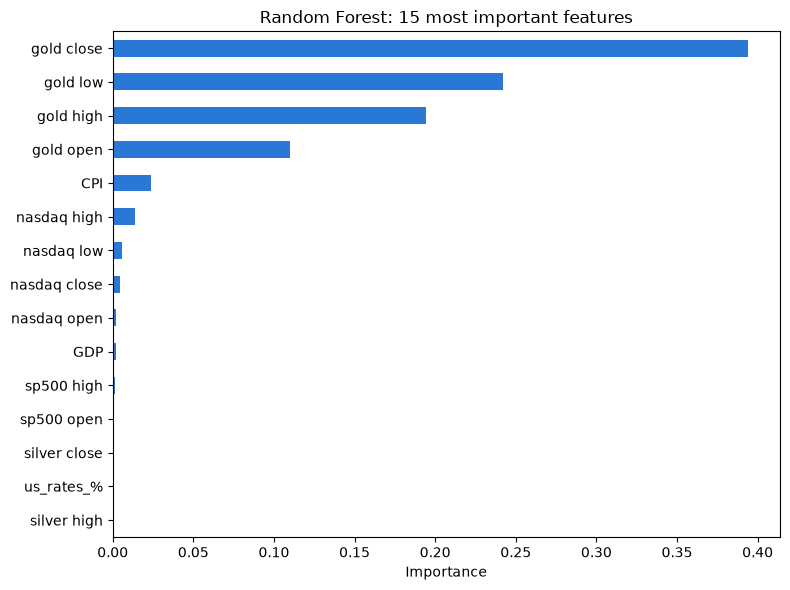

In [42]:
rf = RandomForestRegressor(n_estimators=300,
                           max_depth=None if pd.isna(best_rf["max_depth"]) else int(best_rf["max_depth"]),
                           min_samples_leaf=int(best_rf["min_samples_leaf"]),
                           max_features=best_rf["max_features"],
                           random_state=42, n_jobs=-1).fit(X_train, y_train)
report("Random Forest", rf)

# Feature importance: how much each feature contributes to the forest's splits
importance = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()
importance.tail(15).plot.barh(figsize=(8, 6), color="#2a78d6",
                              title="Random Forest: 15 most important features")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

A random forest averages the predictions of many decision trees, each trained on a random sample of the rows and features. Twenty-seven combinations of three settings were compared on the validation set: the maximum tree depth, the minimum number of training days in each leaf, and the share of features considered at each split. The best combination was max_depth = 10, min_samples_leaf = 3 and max_features = 0.5, with a validation MAE of 1.080. The top settings differ by less than 0.01, so the forest is not sensitive to these choices.

The forest fits the training set noticeably better than the validation set (MAE 0.63 vs 1.08), which shows some overfitting that the other models do not have. Like linear regression, it does not beat the naive baseline.

## Model Comparison

                           Val R2  Val MAE  Test R2  Test MAE  Test RMSE
Model                                                                   
Naive (tomorrow = today)   0.9977   1.0248   0.9977    0.9747     1.3988
DummyRegressor (mean)     -0.0008  25.2558  -0.0011   25.0742    29.1315
Linear Regression          0.9976   1.0312   0.9976    0.9953     1.4170
KNN, all features (k = 4)  0.9894   2.1092   0.9916    1.9626     2.6637
KNN, close prices (k = 4)  0.9968   1.1971   0.9972    1.1083     1.5395
Random Forest              0.9973   1.0798   0.9974    1.0262     1.4779


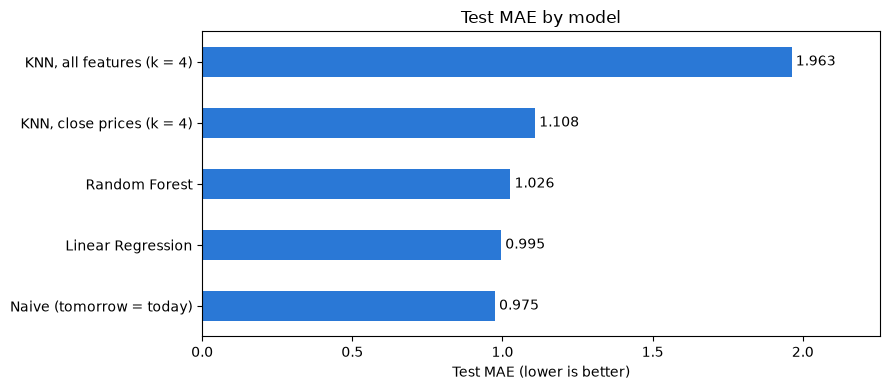

In [43]:
# Each model is scored on the test set once, after all tuning is finished
rows = []
for name, model in models.items():
    va, te = scores(model, X_val, y_val), scores(model, X_test, y_test)
    rows.append({"Model": name, "Val R2": va["R2"], "Val MAE": va["MAE"],
                 "Test R2": te["R2"], "Test MAE": te["MAE"], "Test RMSE": te["RMSE"]})
comparison = pd.DataFrame(rows).set_index("Model")
print(comparison.round(4).to_string())

# Test MAE of each model, excluding the DummyRegressor, whose error is far larger
plot_data = comparison.drop(index="DummyRegressor (mean)")["Test MAE"].sort_values()
ax = plot_data.plot.barh(figsize=(9, 4), color="#2a78d6")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
ax.set_xlabel("Test MAE (lower is better)")
ax.set_ylabel("")
ax.set_title("Test MAE by model")
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

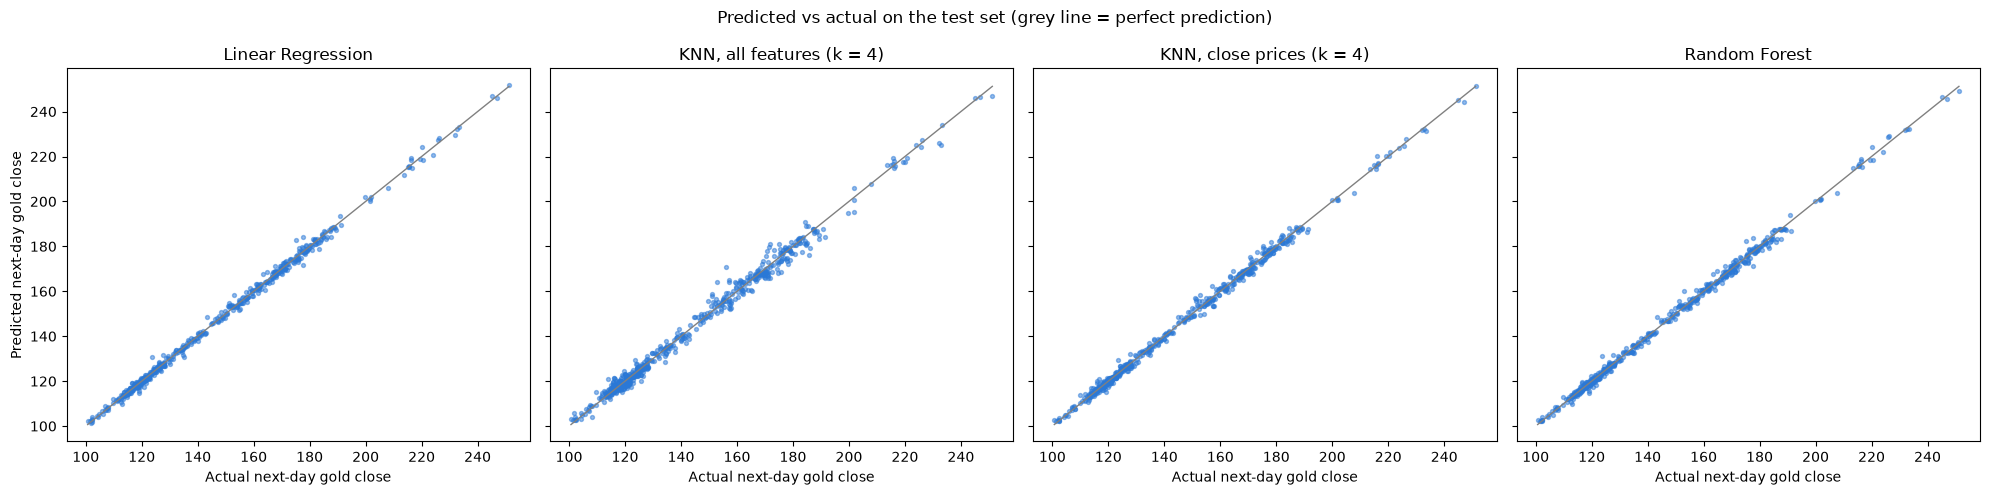

In [44]:
trained = [n for n in models if not n.startswith(("Naive", "Dummy"))]
fig, axes = plt.subplots(1, len(trained), figsize=(5 * len(trained), 5), sharex=True, sharey=True)
for ax, name in zip(axes, trained):
    pred = models[name].predict(X_test)
    ax.scatter(y_test, pred, s=8, alpha=0.5, color="#2a78d6")
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, color="grey", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("Actual next-day gold close")
axes[0].set_ylabel("Predicted next-day gold close")
fig.suptitle("Predicted vs actual on the test set (grey line = perfect prediction)")
plt.tight_layout()
plt.show()

| Model | Test R² | Test MAE | Test RMSE |
|---|---|---|---|
| Naive (tomorrow = today) | 0.9977 | 0.975 | 1.399 |
| Linear Regression | 0.9976 | 0.995 | 1.417 |
| Random Forest | 0.9974 | 1.026 | 1.478 |
| KNN, close prices (k = 4) | 0.9972 | 1.108 | 1.540 |
| KNN, all features (k = 4) | 0.9916 | 1.963 | 2.664 |
| DummyRegressor (mean) | -0.0011 | 25.074 | 29.132 |

All three trained models far outperform the DummyRegressor, reducing the average error from about 25 to about 1. However, **none of them beats the naive baseline** of predicting today's close. Linear regression comes closest (test MAE 0.995 vs 0.975), followed by the random forest (1.026) and KNN with close prices (1.108). The test results follow the same order as the validation results, which suggests the comparison is reliable.

This is consistent with the EDA. Today's gold close already explains almost all of the next day's price, and no other feature showed a meaningful relationship with the next day's *change*. The models therefore learn, in effect, to repeat today's price, and the other features add small errors rather than useful information. This agrees with the efficient-market view that past public prices contain little information about the next day's movement.

Two limitations should be noted. First, because the data was split at random, the days either side of most test days were in the training set, so these scores are likely to be higher than the models would achieve on genuinely future prices (see Section 2.2). Second, R² is almost identical for every trained model (0.997–0.998) because of the strong day-to-day link in price, so it is not a useful way to compare them. MAE and RMSE show the differences more clearly.

# 4. Model Evaluation

The models developed in Section 3 are evaluated in more depth here: whether they overfit, where their errors come from, whether any of them genuinely beats the naive baseline, and how stable the results are.

In [45]:
# MAE on each part of the data for every model from Section 3
fit_rows = []
for name, model in models.items():
    fit_rows.append({"Model": name,
                     "Train MAE": mean_absolute_error(y_train, model.predict(X_train)),
                     "Validation MAE": mean_absolute_error(y_val, model.predict(X_val)),
                     "Test MAE": mean_absolute_error(y_test, model.predict(X_test))})
fit_table = pd.DataFrame(fit_rows).set_index("Model")
fit_table["Test / Train"] = fit_table["Test MAE"] / fit_table["Train MAE"]
print(fit_table.round(3).to_string())

                           Train MAE  Validation MAE  Test MAE  Test / Train
Model                                                                       
Naive (tomorrow = today)       1.046           1.025     0.975         0.932
DummyRegressor (mean)         25.486          25.256    25.074         0.984
Linear Regression              1.042           1.031     0.995         0.955
KNN, all features (k = 4)      1.602           2.109     1.963         1.225
KNN, close prices (k = 4)      0.883           1.197     1.108         1.255
Random Forest                  0.632           1.080     1.026         1.623


### 4.1 Overfitting

| Model | Train MAE | Validation MAE | Test MAE | Test / Train |
|---|---|---|---|---|
| Naive (tomorrow = today) | 1.046 | 1.025 | 0.975 | 0.93 |
| Linear Regression | 1.042 | 1.031 | 0.995 | 0.96 |
| KNN, close prices (k = 4) | 0.883 | 1.197 | 1.108 | 1.25 |
| Random Forest | 0.632 | 1.080 | 1.026 | 1.62 |

Linear regression performs equally well on all three sets, so it does not overfit. KNN and especially the random forest fit the training data much more closely than unseen data: the random forest's test error is 62% higher than its training error. Both have learned patterns specific to the training days that do not carry over to new data, which is why their test errors are higher than linear regression's, despite their lower training errors.

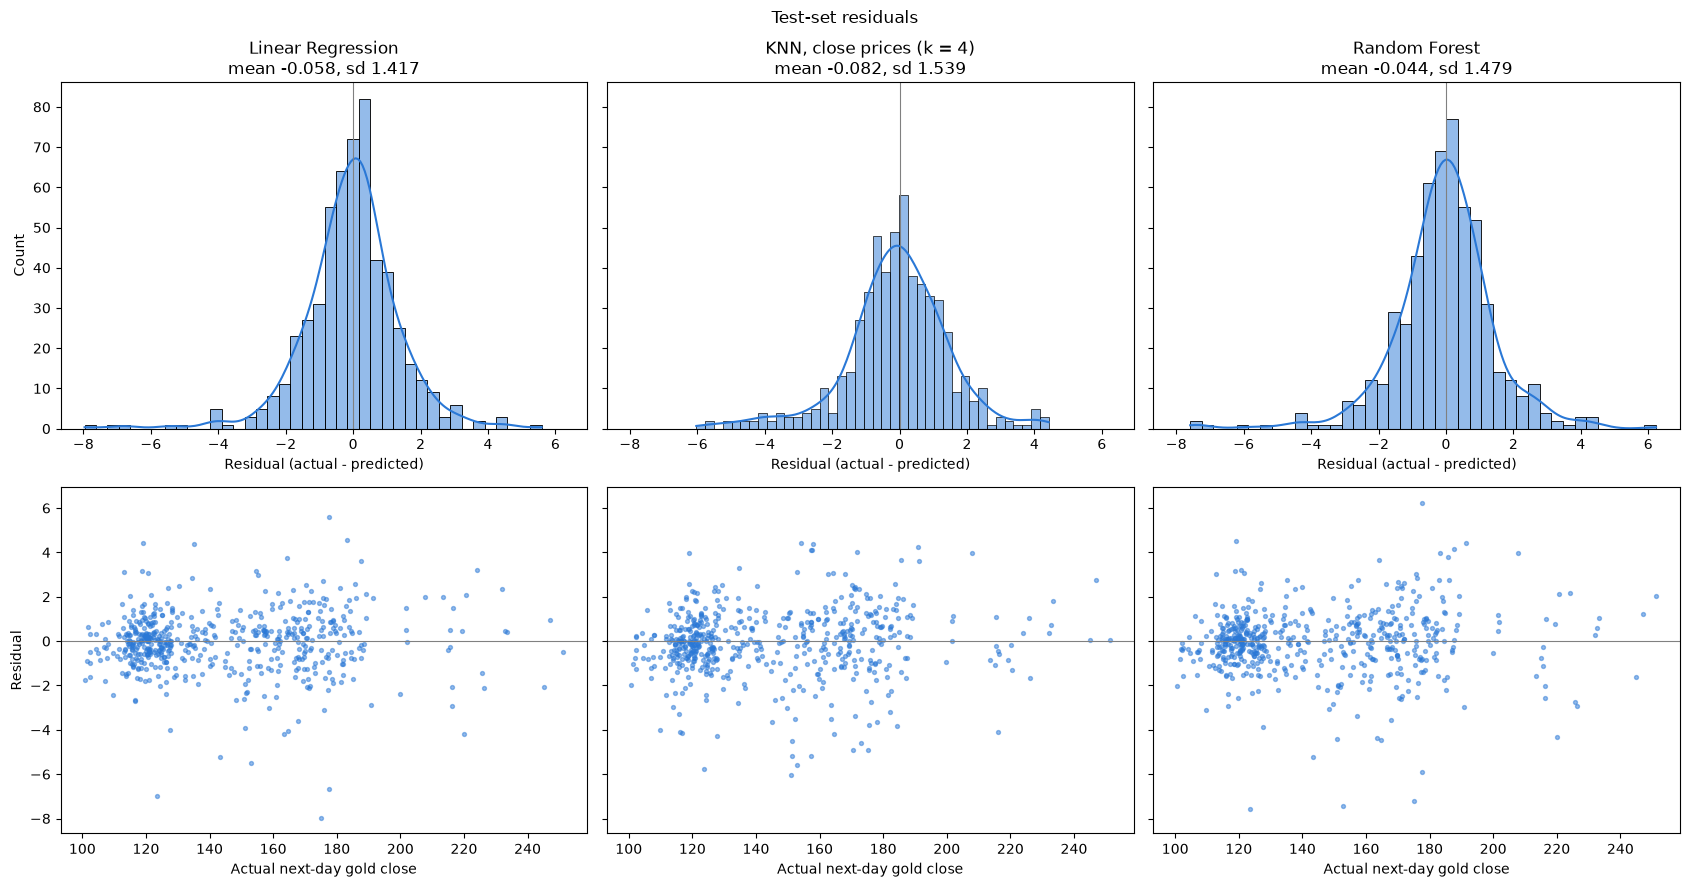

In [47]:
# Residual = actual - predicted, on the test set
knn_name = next(n for n in models if n.startswith("KNN, close prices"))
compare = ["Linear Regression", knn_name, "Random Forest"]
naive_pred = X_test["gold close"].values

fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharex="row", sharey="row")
for j, name in enumerate(compare):
    resid = y_test - models[name].predict(X_test)
    sns.histplot(resid, bins=40, kde=True, color="#2a78d6", ax=axes[0, j])
    axes[0, j].axvline(0, color="grey", linewidth=0.8)
    axes[0, j].set_title(f"{name}\nmean {resid.mean():.3f}, sd {resid.std():.3f}")
    axes[0, j].set_xlabel("Residual (actual - predicted)")

    axes[1, j].scatter(y_test, resid, s=8, alpha=0.5, color="#2a78d6")
    axes[1, j].axhline(0, color="grey", linewidth=0.8)
    axes[1, j].set_xlabel("Actual next-day gold close")
axes[1, 0].set_ylabel("Residual")
fig.suptitle("Test-set residuals")
plt.tight_layout()
plt.show()

In [48]:
# Does the size of the error depend on the price level?
bands = pd.cut(y_test, bins=[100, 125, 150, 175, 200, 260])
band_mae = pd.DataFrame({name: (y_test - models[name].predict(X_test)).abs().groupby(bands, observed=True).mean()
                         for name in ["Naive (tomorrow = today)"] + compare})
band_mae.insert(0, "Days", bands.value_counts().sort_index())
print("Test MAE by price range:")
print(band_mae.round(3).to_string())

Test MAE by price range:
            Days  Naive (tomorrow = today)  Linear Regression  KNN, close prices (k = 4)  Random Forest
target                                                                                                 
(100, 125]   203                     0.734              0.752                      0.851          0.750
(125, 150]   115                     0.880              0.909                      0.986          0.951
(150, 175]   138                     1.097              1.118                      1.433          1.169
(175, 200]    71                     1.400              1.437                      1.408          1.462
(200, 260]    23                     1.525              1.470                      1.114          1.637


### 4.2 Residual analysis

The residuals of all three models are centred close to zero (means between -0.04 and -0.08), so none of them consistently over- or under-predicts. They are roughly bell-shaped but with longer tails than a normal distribution: most errors are under 2, but a few days have errors of 5–8. These are days with unusually large price moves, which no model anticipates.

The residual plots show the errors spreading out as the price rises, and the table confirms it: the naive baseline's MAE grows from 0.73 for prices of 100–125 to 1.53 above 200. This is expected, as a 1% daily move is a larger amount at a higher price. It means MAE is dominated by the high-price days, and a percentage error measure would compare periods more fairly. Above 200 there are only 23 test days, so the differences between models in that range are not reliable.

In [49]:
naive_err = np.abs(y_test.values - naive_pred)
for name in compare:
    err = np.abs(y_test.values - models[name].predict(X_test))
    better = (err < naive_err).mean() * 100
    # Bootstrap: resample test days to estimate how certain the MAE difference is
    rng = np.random.default_rng(42)
    diffs = [(err[i] - naive_err[i]).mean()
             for i in (rng.integers(0, len(err), len(err)) for _ in range(2000))]
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    print(f"{name:<28} beats naive on {better:4.1f}% of days;  "
          f"MAE difference {err.mean() - naive_err.mean():+.3f} (95% CI {lo:+.3f} to {hi:+.3f})")

Linear Regression            beats naive on 51.1% of days;  MAE difference +0.021 (95% CI +0.003 to +0.037)
KNN, close prices (k = 4)    beats naive on 45.5% of days;  MAE difference +0.134 (95% CI +0.049 to +0.225)
Random Forest                beats naive on 46.2% of days;  MAE difference +0.051 (95% CI +0.010 to +0.095)


In [50]:
# 5-fold cross-validation on the training set: does the ranking hold on different samples?
cv = KFold(n_splits=5, shuffle=True, random_state=42)
naive_cv = [mean_absolute_error(y_train.iloc[va], X_train["gold close"].iloc[va])
            for _, va in cv.split(X_train)]
print(f"{'Naive (tomorrow = today)':<28} CV MAE {np.mean(naive_cv):.3f} ± {np.std(naive_cv):.3f}")
for name in compare:
    s = -cross_val_score(models[name], X_train, y_train, cv=cv,
                         scoring="neg_mean_absolute_error", n_jobs=-1)
    print(f"{name:<28} CV MAE {s.mean():.3f} ± {s.std():.3f}")

Naive (tomorrow = today)     CV MAE 1.046 ± 0.027
Linear Regression            CV MAE 1.068 ± 0.023
KNN, close prices (k = 4)    CV MAE 1.248 ± 0.056
Random Forest                CV MAE 1.126 ± 0.036


### 4.3 Comparison with the naive baseline

To test whether the differences from the naive baseline are real or due to chance, the test days were resampled 2,000 times (bootstrapping) to give a 95% confidence interval for each model's MAE minus the baseline's:

| Model | Beats naive on | MAE difference | 95% CI |
|---|---|---|---|
| Linear Regression | 51.1% of days | +0.021 | +0.003 to +0.037 |
| Random Forest | 46.2% of days | +0.051 | +0.010 to +0.095 |
| KNN, close prices | 45.5% of days | +0.134 | +0.049 to +0.225 |

All three intervals lie entirely above zero, so all three models are **genuinely worse** than predicting today's price, not just unlucky on this test set. Linear regression is better than the baseline on slightly more than half of the days, but its occasional larger errors outweigh this.

Five-fold cross-validation on the training set gives the same ranking: naive 1.046 ± 0.027, linear regression 1.068 ± 0.023, random forest 1.126 ± 0.036 and KNN 1.248 ± 0.056. The ranking is therefore stable across different samples of the data.

# 5. Further Modelling Improvements

The evaluation suggests two causes of the models' weakness. First, they predict the *price*, of which today's close already explains almost everything, so they spend their effort relearning that and add noise. Second, the features describe a single day and contain no information about recent movement. Two improvements are tested, one for each cause, and each is judged on the validation set before anything is tested.

In [51]:
# Target: next day's change in price instead of the price itself.
# Predictions are converted back to a price by adding today's close.
y_train_chg = y_train - X_train["gold close"]

rf_params = dict(n_estimators=300, max_depth=10, min_samples_leaf=3,
                 max_features=0.5, random_state=42, n_jobs=-1)   # best settings from Section 3

def change_models(cols):
    return {
        "Linear Regression": make_pipeline(FunctionTransformer(lambda X_part: X_part[cols]),
                                           StandardScaler(), LinearRegression()),
        "KNN": make_pipeline(FunctionTransformer(lambda X_part: X_part[cols]),
                             StandardScaler(), KNeighborsRegressor(n_neighbors=50)),
        "Random Forest": make_pipeline(FunctionTransformer(lambda X_part: X_part[cols]),
                                       RandomForestRegressor(**rf_params)),
    }

def evaluate_change(model, Xtr, Xva):
    model.fit(Xtr, y_train_chg)
    pred_price = Xva["gold close"].values + model.predict(Xva)
    return mean_absolute_error(y_val, pred_price), r2_score(y_val - Xva["gold close"], model.predict(Xva))

print(f"{'Naive (tomorrow = today)':<20} validation MAE {mean_absolute_error(y_val, X_val['gold close']):.3f}")
for name, model in change_models(close_cols).items():
    mae, r2_chg = evaluate_change(model, X_train, X_val)
    print(f"{name:<20} validation MAE {mae:.3f}   R^2 on the change: {r2_chg:+.3f}")

Naive (tomorrow = today) validation MAE 1.025
Linear Regression    validation MAE 1.032   R^2 on the change: -0.003
KNN                  validation MAE 1.034   R^2 on the change: -0.018
Random Forest        validation MAE 1.028   R^2 on the change: -0.017


### 5.1 Predicting the change instead of the price

The target is changed to the next day's change in price (tomorrow's close minus today's), and the prediction is converted back to a price by adding today's close. Today's price is then built into every prediction, and the models only have to learn whether the price will move up or down. KNN uses k = 50 here: because the daily change is mostly random, averaging over many similar days keeps its predictions close to zero rather than copying the noise of a few neighbours.

This brings every model to almost exactly the baseline's validation MAE (1.028–1.034 vs 1.025), and removes most of the gap seen in Section 3. However, R² on the change itself is slightly negative for all three models (-0.003 to -0.018): none of them predicts the direction of the next day's move better than assuming no change.

In [52]:
# Features describing recent movement, calculated on the full consecutive series
# so that each row only uses that day and earlier days.
eng = pd.DataFrame(index=price.index)
for asset in ["gold", "silver", "platinum", "sp500", "oil"]:
    close = price[f"{asset} close"]
    eng[f"{asset} return 1d"] = close.pct_change() * 100
    eng[f"{asset} return 5d"] = close.pct_change(5) * 100
eng["usd_chf return 1d"] = price["usd_chf"].pct_change() * 100
eng["gold vs 20d average %"] = (price["gold close"] / price["gold close"].rolling(20).mean() - 1) * 100
eng["gold volatility 20d"] = (price["gold close"].pct_change() * 100).rolling(20).std()
eng["gold range %"] = (price["gold high"] - price["gold low"]) / price["gold close"] * 100

# The first 20 days have no rolling values; fill with the median so no rows are lost
eng = eng.fillna(eng.median())
eng_cols = list(eng.columns)

X_train_eng = X_train.join(eng)
X_val_eng = X_val.join(eng)
X_test_eng = X_test.join(eng)

# Correlation of each engineered feature with the next day's change (training set)
print("Correlation with the next day's change in gold (training set):")
print(X_train_eng[eng_cols].corrwith(y_train_chg).round(3).sort_values().to_string())

Correlation with the next day's change in gold (training set):
oil return 1d           -0.037
gold range %            -0.023
oil return 5d           -0.017
gold vs 20d average %   -0.014
silver return 1d        -0.005
silver return 5d        -0.004
sp500 return 1d         -0.000
usd_chf return 1d       -0.000
platinum return 5d       0.005
gold return 5d           0.006
gold volatility 20d      0.009
gold return 1d           0.010
platinum return 1d       0.012
sp500 return 5d          0.032


In [53]:
eng_set = close_cols + eng_cols
rows = []
for name, model in change_models(close_cols).items():
    rows.append({"Model": name, "Target": "change", "Features": "close prices",
                 "Validation MAE": evaluate_change(model, X_train, X_val)[0]})
for name, model in change_models(eng_set).items():
    rows.append({"Model": name, "Target": "change", "Features": "close prices + engineered",
                 "Validation MAE": evaluate_change(model, X_train_eng, X_val_eng)[0]})
for name in compare:
    rows.append({"Model": name.split(",")[0], "Target": "price", "Features": "Section 3 model",
                 "Validation MAE": mean_absolute_error(y_val, models[name].predict(X_val))})
rows.append({"Model": "Naive (tomorrow = today)", "Target": "-", "Features": "gold close",
             "Validation MAE": mean_absolute_error(y_val, X_val["gold close"])})
improve_table = pd.DataFrame(rows).sort_values("Validation MAE")
print(improve_table.round(3).to_string(index=False))

                   Model Target                  Features  Validation MAE
Naive (tomorrow = today)      -                gold close           1.025
           Random Forest change              close prices           1.028
       Linear Regression  price           Section 3 model           1.031
       Linear Regression change              close prices           1.032
                     KNN change              close prices           1.034
           Random Forest change close prices + engineered           1.037
       Linear Regression change close prices + engineered           1.040
                     KNN change close prices + engineered           1.048
           Random Forest  price           Section 3 model           1.080
                     KNN  price           Section 3 model           1.197


### 5.2 Engineered features

Fourteen features describing recent movement were added: 1-day and 5-day returns of gold, silver, platinum, sp500 and oil, the 1-day change in usd_chf, how far gold is above or below its 20-day average, its 20-day volatility, and its daily range as a percentage of its price. Each is calculated only from that day and earlier days, so no future information is used.

None of them is related to the next day's change in gold: all correlations lie between -0.04 and +0.03. Adding them made every model slightly *worse* on the validation set (for example, random forest 1.028 → 1.037), because they give the models more noise to fit. This improvement is therefore rejected, and only the change target is taken forward to the test set.

                               Test MAE  Test RMSE          vs naive (95% CI)
Model                                                                        
KNN (improved)                    0.963      1.393  -0.011 (-0.027 to +0.005)
Random Forest (improved)          0.972      1.388  -0.003 (-0.022 to +0.016)
Naive (tomorrow = today)          0.975      1.399                          -
Linear Regression (improved)      0.977      1.397  +0.002 (-0.007 to +0.011)
Linear Regression (Section 3)     0.995      1.417  +0.021 (+0.003 to +0.037)
Random Forest (Section 3)         1.026      1.478  +0.051 (+0.010 to +0.095)
KNN (Section 3)                   1.108      1.540  +0.134 (+0.049 to +0.225)


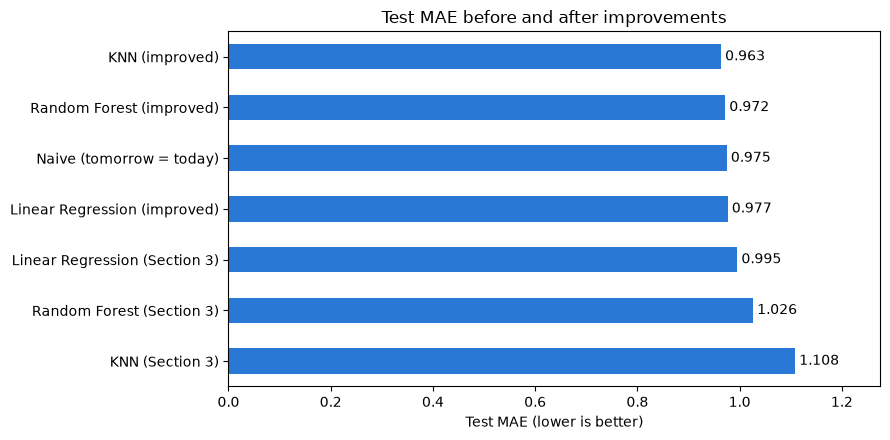

In [54]:
# Validation chose the change target with the close-price features
# (the engineered features did not help), so that version is tested here.
naive_err = np.abs(y_test.values - X_test["gold close"].values)
test_rows = [{"Model": "Naive (tomorrow = today)", "Test MAE": naive_err.mean(),
              "Test RMSE": np.sqrt((naive_err ** 2).mean()), "vs naive (95% CI)": "-"}]

def add_row(label, pred):
    err = np.abs(y_test.values - pred)
    rng = np.random.default_rng(42)
    diffs = [(err[i] - naive_err[i]).mean()
             for i in (rng.integers(0, len(err), len(err)) for _ in range(2000))]
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    test_rows.append({"Model": label, "Test MAE": err.mean(),
                      "Test RMSE": np.sqrt((err ** 2).mean()),
                      "vs naive (95% CI)": f"{err.mean() - naive_err.mean():+.3f} ({lo:+.3f} to {hi:+.3f})"})

for name, model in change_models(close_cols).items():
    model.fit(X_train, y_train_chg)
    add_row(f"{name} (improved)", X_test["gold close"].values + model.predict(X_test))
for name in compare:
    add_row(f"{name.split(',')[0]} (Section 3)", models[name].predict(X_test))

final_table = pd.DataFrame(test_rows).set_index("Model").sort_values("Test MAE")
print(final_table.round(3).to_string())

ax = final_table["Test MAE"].sort_values(ascending=False).plot.barh(figsize=(9, 4.5), color="#2a78d6")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
ax.set_xlabel("Test MAE (lower is better)")
ax.set_ylabel("")
ax.set_title("Test MAE before and after improvements")
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

### 5.3 Results of the improvements

| Model | Test MAE | Test RMSE | Difference from naive (95% CI) |
|---|---|---|---|
| KNN (improved) | 0.963 | 1.393 | -0.011 (-0.027 to +0.005) |
| Random Forest (improved) | 0.972 | 1.388 | -0.003 (-0.022 to +0.016) |
| Naive (tomorrow = today) | 0.975 | 1.399 | – |
| Linear Regression (improved) | 0.977 | 1.397 | +0.002 (-0.007 to +0.011) |
| Linear Regression (Section 3) | 0.995 | 1.417 | +0.021 (+0.003 to +0.037) |
| Random Forest (Section 3) | 1.026 | 1.478 | +0.051 (+0.010 to +0.095) |
| KNN (Section 3) | 1.108 | 1.540 | +0.134 (+0.049 to +0.225) |

Predicting the change instead of the price clearly improved all three models. Their test MAE fell by 0.018 (linear regression), 0.054 (random forest) and 0.145 (KNN), and none of them is now significantly worse than the naive baseline. Improved KNN and random forest have a slightly lower MAE than the baseline. However, their confidence intervals include zero, so this difference could be due to chance, and none of the models can be said to beat the baseline.

### 5.4 Conclusion and further work

The best achievable result with this data is to match the naive prediction that tomorrow's gold price will equal today's. This agrees with every stage of the analysis: the EDA found no feature related to the next day's change, the residuals show large unpredictable moves, and the extra features made the models worse. It is consistent with the efficient-market view that publicly available prices already reflect known information.

Further work could include:
- **A chronological split**, to measure performance on genuinely future data and remove the optimism of the random split (Section 2.2).
- **A percentage error measure** such as MAPE, so that high-price days do not dominate the comparison.
- **Classification of the direction of the move** (up or down), which directly tests whether any model predicts direction better than chance.
- **Information not in this dataset**, such as news, central bank announcements or market sentiment, which drive the large unexpected moves seen in the residuals.

# 6. Summary of Results

The aim was to predict the next trading day's gold ETF closing price from market, currency and economic data. Four algorithms were compared with a naive baseline that predicts tomorrow's price will equal today's.

| Model | Test MAE (price target) | Test MAE (change target) |
|---|---|---|
| DummyRegressor (mean) | 25.074 | – |
| Linear Regression | 0.995 | 0.977 |
| KNN | 1.108 | 0.963 |
| Random Forest | 1.026 | 0.972 |
| **Naive baseline** | **0.975** | **0.975** |

- **All trained models far outperform the DummyRegressor**, reducing the average error from about 25 to about 1.
- **No model beat the naive baseline.** Predicting the price directly made all three models significantly worse than the baseline. Predicting the next day's *change* instead brought them level with it: KNN and the random forest were marginally better, but within the margin of chance.
- **Today's gold price is the only strong predictor.** The EDA found that same-day movements in silver, platinum and the US dollar are linked to gold, but no feature, including 14 engineered features of recent movement, was related to the next day's change.
- **Removing duplicate features helped distance-based models.** KNN's error halved when the redundant open/high/low prices were removed.
- **Limitation:** the random split puts neighbouring days in the training set, so these scores are likely to be optimistic for predicting genuinely future prices.

Overall, the next day's gold price could not be predicted more accurately than by assuming it will not change. This is consistent with the efficient-market view that current prices already reflect publicly available information.